In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = PROJECT_ROOT / "data" / "raw" / "data.csv"

df = pd.read_csv(DATA_PATH, sep=";")

# Clean column names
df.columns = df.columns.str.strip()

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)


Dataset loaded successfully!
Dataset shape: (4424, 37)


In [2]:

display(df.head(10))


,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate
5,2,39,1,9991,0,19,133.1,1,37,37,...,0,5,17,5,11.500000,5,16.2,0.3,-0.92,Graduate
6,1,1,1,9500,1,1,142.0,1,19,38,...,0,8,8,8,14.345000,0,15.5,2.8,-4.06,Graduate
7,1,18,4,9254,1,1,119.0,1,37,37,...,0,5,5,0,0.000000,0,15.5,2.8,-4.06,Dropout
8,1,1,3,9238,1,1,137.0,62,1,1,...,0,6,7,6,14.142857,0,16.2,0.3,-0.92,Graduate
9,1,1,1,9238,1,1,138.0,1,1,19,...,0,6,14,2,13.500000,0,8.9,1.4,3.51,Dropout


In [3]:

for column in df.columns:
    print(f"\nColumn: {column}")
    print("Data type:", df[column].dtype)
    print("Unique values:", df[column].nunique())
    print("Sample values:", df[column].unique()[:15])



Column: Marital status
Data type: int64
Unique values: 6
Sample values: [1 2 4 3 5 6]

Column: Application mode
Data type: int64
Unique values: 18
Sample values: [17 15  1 39 18 53 44 51 43  7 42 16  5  2 10]

Column: Application order
Data type: int64
Unique values: 8
Sample values: [5 1 2 4 3 6 9 0]

Column: Course
Data type: int64
Unique values: 17
Sample values: [ 171 9254 9070 9773 8014 9991 9500 9238 9670 9853 9085 9130 9556 9147
 9003]

Column: Daytime/evening attendance
Data type: int64
Unique values: 2
Sample values: [1 0]

Column: Previous qualification
Data type: int64
Unique values: 17
Sample values: [ 1 19 42 39 10  3 40  2  4 12 43 15  6  9 38]

Column: Previous qualification (grade)
Data type: float64
Unique values: 101
Sample values: [122.  160.  100.  133.1 142.  119.  137.  138.  139.  136.  133.  110.
 149.  127.  135. ]

Column: Nacionality
Data type: int64
Unique values: 21
Sample values: [  1  62   6  41  26 103  13  25  21 101  11  22  32 100  24]

Column: Mothe

In [4]:

numerical_features = [
    "Previous qualification (grade)",
    "Admission grade",
    "Age at enrollment",
    "Unemployment rate",
    "Inflation rate",
    "GDP"
]

ordinal_features = [
    "Application order"
]

binary_features = [
    "Daytime/evening attendance",
    "Displaced",
    "Educational special needs",
    "Debtor",
    "Tuition fees up to date",
    "Gender",
    "Scholarship holder",
    "International"
]

semester_features = [
    col for col in df.columns
    if col.startswith("Curricular units")
]

target_column = "Target"

categorical_features = [
    col for col in df.columns
    if col not in (
        numerical_features
        + ordinal_features
        + binary_features
        + semester_features
        + [target_column]
    )
]

feature_dictionary = pd.DataFrame({
    "Feature": numerical_features + ordinal_features
               + binary_features + categorical_features
               + semester_features,
    "Category": (
        ["Numerical"] * len(numerical_features)
        + ["Ordinal"] * len(ordinal_features)
        + ["Binary categorical"] * len(binary_features)
        + ["Nominal categorical"] * len(categorical_features)
        + ["Semester academic performance"] * len(semester_features)
    )
})

display(feature_dictionary)
print("\nFeature category counts:")
display(feature_dictionary["Category"].value_counts())


,Feature,Category
0,Previous qualification (grade),Numerical
1,Admission grade,Numerical
2,Age at enrollment,Numerical
3,Unemployment rate,Numerical
4,Inflation rate,Numerical
5,GDP,Numerical
6,Application order,Ordinal
7,Daytime/evening attendance,Binary categorical
8,Displaced,Binary categorical
9,Educational special needs,Binary categorical



Feature category counts:


Category
Semester academic performance    12
Nominal categorical               9
Binary categorical                8
Numerical                         6
Ordinal                           1
Name: count, dtype: int64

In [5]:

from ucimlrepo import fetch_ucirepo

# Retrieve official UCI dataset metadata
uci_dataset = fetch_ucirepo(id=697)

# Get the official variable descriptions
variable_info = uci_dataset.variables

display(variable_info)


,name,role,type,demographic,description,units,missing_values
0,Marital Status,Feature,Integer,Marital Status,1 – single 2 – married 3 – widower 4 – divorce...,None,no
1,Application mode,Feature,Integer,NaN,1 - 1st phase - general contingent 2 - Ordinan...,None,no
2,Application order,Feature,Integer,NaN,Application order (between 0 - first choice; a...,None,no
3,Course,Feature,Integer,NaN,33 - Biofuel Production Technologies 171 - Ani...,None,no
4,Daytime/evening attendance,Feature,Integer,NaN,1 – daytime 0 - evening,None,no
5,Previous qualification,Feature,Integer,Education Level,1 - Secondary education 2 - Higher education -...,None,no
6,Previous qualification (grade),Feature,Continuous,NaN,Grade of previous qualification (between 0 and...,None,no
7,Nacionality,Feature,Integer,Nationality,1 - Portuguese; 2 - German; 6 - Spanish; 11 - ...,None,no
8,Mother's qualification,Feature,Integer,Education Level,1 - Secondary Education - 12th Year of Schooli...,None,no
9,Father's qualification,Feature,Integer,Education Level,1 - Secondary Education - 12th Year of Schooli...,None,no


In [6]:

print("Official UCI variable documentation")

for _, row in variable_info.iterrows():
    print("\n" + "=" * 70)
    print("Variable:", row["name"])
    print("Role:", row["role"])
    print("Type:", row["type"])
    print("Description:", row["description"])
    print("Missing values:", row["missing_values"])


Official UCI variable documentation

Variable: Marital Status
Role: Feature
Type: Integer
Description: 1 – single 2 – married 3 – widower 4 – divorced 5 – facto union 6 – legally separated
Missing values: no

Variable: Application mode
Role: Feature
Type: Integer
Description: 1 - 1st phase - general contingent 2 - Ordinance No. 612/93 5 - 1st phase - special contingent (Azores Island) 7 - Holders of other higher courses 10 - Ordinance No. 854-B/99 15 - International student (bachelor) 16 - 1st phase - special contingent (Madeira Island) 17 - 2nd phase - general contingent 18 - 3rd phase - general contingent 26 - Ordinance No. 533-A/99, item b2) (Different Plan) 27 - Ordinance No. 533-A/99, item b3 (Other Institution) 39 - Over 23 years old 42 - Transfer 43 - Change of course 44 - Technological specialization diploma holders 51 - Change of institution/course 53 - Short cycle diploma holders 57 - Change of institution/course (International)
Missing values: no

Variable: Application order

In [7]:

occupation_mapping = {
    0: "Student",
    1: "Legislative and executive representatives, directors and managers",
    2: "Specialists in intellectual and scientific activities",
    3: "Intermediate-level technicians and professionals",
    4: "Administrative staff",
    5: "Personal services, security and sales workers",
    6: "Skilled agricultural, fishing and forestry workers",
    7: "Skilled industry, construction and craft workers",
    8: "Installation and machine operators and assemblers",
    9: "Unskilled workers",
    10: "Armed forces professions",
    90: "Other situation",
    99: "Blank"
}

print("Mother's occupation:")
display(
    df["Mother's occupation"]
    .map(occupation_mapping)
    .value_counts()
    .to_frame("Count")
)

print("Father's occupation:")
display(
    df["Father's occupation"]
    .map(occupation_mapping)
    .value_counts()
    .to_frame("Count")
)


Mother's occupation:


,Count
Mother's occupation,
Unskilled workers,1577
Administrative staff,817
"Personal services, security and sales workers",530
Intermediate-level technicians and professionals,351
Specialists in intellectual and scientific activities,318
"Skilled industry, construction and craft workers",272
Student,144
"Legislative and executive representatives, directors and managers",102
"Skilled agricultural, fishing and forestry workers",91


Father's occupation:


,Count
Father's occupation,
Unskilled workers,1010
"Skilled industry, construction and craft workers",666
"Personal services, security and sales workers",516
Administrative staff,386
Intermediate-level technicians and professionals,384
Installation and machine operators and assemblers,318
Armed forces professions,266
"Skilled agricultural, fishing and forestry workers",242
Specialists in intellectual and scientific activities,197


In [8]:
occupation_columns = [
    "Mother's occupation",
    "Father's occupation"
]

for col in occupation_columns:
    print(f"\n{col}")
    print("-" * 50)
    print("Unique codes:", sorted(df[col].unique()))
    print("\nCode frequencies:")
    display(df[col].value_counts().sort_index().to_frame("Count"))


Mother's occupation
--------------------------------------------------
Unique codes: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(90), np.int64(99), np.int64(122), np.int64(123), np.int64(125), np.int64(131), np.int64(132), np.int64(134), np.int64(141), np.int64(143), np.int64(144), np.int64(151), np.int64(152), np.int64(153), np.int64(171), np.int64(173), np.int64(175), np.int64(191), np.int64(192), np.int64(193), np.int64(194)]

Code frequencies:


,Count
Mother's occupation,
0,144
1,102
2,318
3,351
4,817
5,530
6,91
7,272
8,36



Father's occupation
--------------------------------------------------
Unique codes: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(90), np.int64(99), np.int64(101), np.int64(102), np.int64(103), np.int64(112), np.int64(114), np.int64(121), np.int64(122), np.int64(123), np.int64(124), np.int64(131), np.int64(132), np.int64(134), np.int64(135), np.int64(141), np.int64(143), np.int64(144), np.int64(151), np.int64(152), np.int64(153), np.int64(154), np.int64(161), np.int64(163), np.int64(171), np.int64(172), np.int64(174), np.int64(175), np.int64(181), np.int64(182), np.int64(183), np.int64(192), np.int64(193), np.int64(194), np.int64(195)]

Code frequencies:


,Count
Father's occupation,
0,128
1,134
2,197
3,384
4,386
5,516
6,242
7,666
8,318


In [9]:
mother_occupation_mapping = {
    0: "Student",
    1: "Legislative and executive representatives, directors and managers",
    2: "Intellectual and scientific specialists",
    3: "Intermediate-level technicians and professionals",
    4: "Administrative staff",
    5: "Personal services, security and sales workers",
    6: "Agriculture, fisheries and forestry skilled workers",
    7: "Industry, construction and craft workers",
    8: "Machine operators and assembly workers",
    9: "Unskilled workers",
    10: "Armed forces professions",
    90: "Other situation",
    99: "Blank category",
    122: "Health professionals",
    123: "Teachers",
    125: "ICT specialists",
    131: "Science and engineering technicians",
    132: "Health technicians and professionals",
    134: "Legal, social, sports and cultural service technicians",
    141: "Office workers, secretaries and data-processing operators",
    143: "Accounting, statistical and financial service operators",
    144: "Other administrative support staff",
    151: "Personal service workers",
    152: "Sellers",
    153: "Personal care workers",
    171: "Skilled construction workers",
    173: "Printing, precision instrument and jewellery workers",
    175: "Food processing, woodworking, clothing and craft workers",
    191: "Cleaning workers",
    192: "Unskilled agricultural and forestry workers",
    193: "Unskilled extractive, construction, manufacturing and transport workers",
    194: "Meal preparation assistants"
}

father_occupation_mapping = {
    0: "Student",
    1: "Legislative and executive representatives, directors and managers",
    2: "Intellectual and scientific specialists",
    3: "Intermediate-level technicians and professionals",
    4: "Administrative staff",
    5: "Personal services, security and sales workers",
    6: "Agriculture, fisheries and forestry skilled workers",
    7: "Industry, construction and craft workers",
    8: "Machine operators and assembly workers",
    9: "Unskilled workers",
    10: "Armed forces professions",
    90: "Other situation",
    99: "Blank category",
    101: "Armed forces officers",
    102: "Armed forces sergeants",
    103: "Other armed forces personnel",
    112: "Administrative and commercial services directors",
    114: "Hotel, catering, trade and other services directors",
    121: "Physical science, mathematics and engineering specialists",
    122: "Health professionals",
    123: "Teachers",
    124: "Finance, accounting and administrative organisation specialists",
    131: "Science and engineering technicians",
    132: "Health technicians and professionals",
    134: "Legal, social, sports and cultural service technicians",
    135: "ICT technicians",
    141: "Office workers, secretaries and data-processing operators",
    143: "Accounting, statistical and financial service operators",
    144: "Other administrative support staff",
    151: "Personal service workers",
    152: "Sellers",
    153: "Personal care workers",
    154: "Protection and security service personnel",
    161: "Market-oriented farmers and skilled agricultural workers",
    163: "Subsistence farmers, livestock keepers, fishers and hunters",
    171: "Skilled construction workers",
    172: "Metallurgy and metalworking workers",
    174: "Electricity and electronics workers",
    175: "Food processing, woodworking, clothing and craft workers",
    181: "Fixed plant and machine operators",
    182: "Assembly workers",
    183: "Vehicle drivers and mobile equipment operators",
    192: "Unskilled agricultural and forestry workers",
    193: "Unskilled extractive, construction, manufacturing and transport workers",
    194: "Meal preparation assistants",
    195: "Street vendors and street service providers"
}

In [10]:
df["Mother's occupation description"] = (
    df["Mother's occupation"].map(mother_occupation_mapping)
)

df["Father's occupation description"] = (
    df["Father's occupation"].map(father_occupation_mapping)
)

# Check whether every code was successfully mapped
for col in [
    "Mother's occupation description",
    "Father's occupation description"
]:
    print(f"\n{col}")
    print("Unmapped records:", df[col].isna().sum())
    display(df[col].value_counts().to_frame("Count"))


Mother's occupation description
Unmapped records: 0


,Count
Mother's occupation description,
Unskilled workers,1577
Administrative staff,817
"Personal services, security and sales workers",530
Intermediate-level technicians and professionals,351
Intellectual and scientific specialists,318
"Industry, construction and craft workers",272
Student,144
"Legislative and executive representatives, directors and managers",102
"Agriculture, fisheries and forestry skilled workers",91



Father's occupation description
Unmapped records: 0


,Count
Father's occupation description,
Unskilled workers,1010
"Industry, construction and craft workers",666
"Personal services, security and sales workers",516
Administrative staff,386
Intermediate-level technicians and professionals,384
Machine operators and assembly workers,318
Armed forces professions,266
"Agriculture, fisheries and forestry skilled workers",242
Intellectual and scientific specialists,197


In [11]:
# Create a percentage table for mother's occupation
mother_occupation_analysis = pd.crosstab(
    df["Mother's occupation description"],
    df["Target"],
    normalize="columns"
) * 100

# Sort by overall frequency
mother_occupation_analysis["Total"] = (
    df["Mother's occupation description"]
    .value_counts(normalize=True) * 100
)

mother_occupation_analysis = mother_occupation_analysis.sort_values(
    by="Total",
    ascending=False
)

display(mother_occupation_analysis.round(2))

Target,Dropout,Enrolled,Graduate,Total
Mother's occupation description,,,,
Unskilled workers,34.48,33.25,37.26,35.65
Administrative staff,17.45,18.51,19.10,18.47
"Personal services, security and sales workers",10.98,11.84,12.68,11.98
Intermediate-level technicians and professionals,6.69,9.95,8.01,7.93
Intellectual and scientific specialists,7.18,9.82,6.25,7.19
"Industry, construction and craft workers",5.63,6.05,6.52,6.15
Student,6.97,0.13,1.99,3.25
"Legislative and executive representatives, directors and managers",2.74,1.89,2.17,2.31
"Agriculture, fisheries and forestry skilled workers",1.83,1.76,2.31,2.06


In [12]:
father_occupation_analysis = pd.crosstab(
    df["Father's occupation description"],
    df["Target"],
    normalize="columns"
) * 100

father_occupation_analysis["Total"] = (
    df["Father's occupation description"]
    .value_counts(normalize=True) * 100
)

father_occupation_analysis = father_occupation_analysis.sort_values(
    by="Total",
    ascending=False
)

display(father_occupation_analysis.round(2))

Target,Dropout,Enrolled,Graduate,Total
Father's occupation description,,,,
Unskilled workers,22.73,20.53,23.72,22.83
"Industry, construction and craft workers",12.95,13.98,16.79,15.05
"Personal services, security and sales workers",10.42,13.48,11.82,11.66
Administrative staff,9.78,9.32,7.83,8.73
Intermediate-level technicians and professionals,8.02,7.93,9.37,8.68
Machine operators and assembly workers,6.62,6.93,7.65,7.19
Armed forces professions,5.98,6.80,5.75,6.01
"Agriculture, fisheries and forestry skilled workers",4.86,6.05,5.66,5.47
Intellectual and scientific specialists,4.93,6.30,3.49,4.45


In [13]:
mother_dropout_rate = pd.crosstab(
    df["Mother's occupation description"],
    df["Target"],
    normalize="index"
) * 100

mother_dropout_rate = mother_dropout_rate.sort_values(
    by="Dropout",
    ascending=False
)

display(mother_dropout_rate.round(2))

Target,Dropout,Enrolled,Graduate
Mother's occupation description,,,
Blank category,76.47,11.76,11.76
Other situation,72.86,0.00,27.14
Student,68.75,0.69,30.56
Machine operators and assembly workers,41.67,19.44,38.89
"Legislative and executive representatives, directors and managers",38.24,14.71,47.06
Intellectual and scientific specialists,32.08,24.53,43.40
Unskilled workers,31.07,16.74,52.19
Administrative staff,30.35,17.99,51.65
"Personal services, security and sales workers",29.43,17.74,52.83


In [14]:
father_dropout_rate = pd.crosstab(
    df["Father's occupation description"],
    df["Target"],
    normalize="index"
) * 100

father_dropout_rate = father_dropout_rate.sort_values(
    by="Dropout",
    ascending=False
)

display(father_dropout_rate.round(2))

Target,Dropout,Enrolled,Graduate
Father's occupation description,,,
Other situation,70.77,0.00,29.23
Blank category,68.42,10.53,21.05
Student,64.06,2.34,33.59
Meal preparation assistants,50.00,0.00,50.00
Administrative and commercial services directors,50.00,50.00,0.00
Administrative staff,36.01,19.17,44.82
"Legislative and executive representatives, directors and managers",35.82,17.16,47.01
Intellectual and scientific specialists,35.53,25.38,39.09
Sellers,33.33,66.67,0.00


In [15]:
def occupation_dropout_summary(data, occupation_column):
    # Count students in each occupation and outcome
    counts = pd.crosstab(
        data[occupation_column],
        data["Target"]
    )

    # Calculate outcome percentages within each occupation
    percentages = pd.crosstab(
        data[occupation_column],
        data["Target"],
        normalize="index"
    ) * 100

    summary = pd.DataFrame({
        "Total Students": counts.sum(axis=1),
        "Dropout Count": counts["Dropout"],
        "Dropout Rate (%)": percentages["Dropout"],
        "Graduate Rate (%)": percentages["Graduate"],
        "Enrolled Rate (%)": percentages["Enrolled"]
    })

    return summary.sort_values(
        by="Dropout Rate (%)",
        ascending=False
    )


mother_summary = occupation_dropout_summary(
    df,
    "Mother's occupation description"
)

father_summary = occupation_dropout_summary(
    df,
    "Father's occupation description"
)

# Categories with at least 30 students
print("MOTHER'S OCCUPATION — CATEGORIES WITH AT LEAST 30 STUDENTS")
display(
    mother_summary[mother_summary["Total Students"] >= 30].round(2)
)

print("FATHER'S OCCUPATION — CATEGORIES WITH AT LEAST 30 STUDENTS")
display(
    father_summary[father_summary["Total Students"] >= 30].round(2)
)

# Small categories that need cautious interpretation
print("MOTHER'S OCCUPATION — CATEGORIES WITH FEWER THAN 30 STUDENTS")
display(
    mother_summary[mother_summary["Total Students"] < 30].round(2)
)

print("FATHER'S OCCUPATION — CATEGORIES WITH FEWER THAN 30 STUDENTS")
display(
    father_summary[father_summary["Total Students"] < 30].round(2)
)

MOTHER'S OCCUPATION — CATEGORIES WITH AT LEAST 30 STUDENTS


,Total Students,Dropout Count,Dropout Rate (%),Graduate Rate (%),Enrolled Rate (%)
Mother's occupation description,,,,,
Other situation,70,51,72.86,27.14,0.00
Student,144,99,68.75,30.56,0.69
Machine operators and assembly workers,36,15,41.67,38.89,19.44
"Legislative and executive representatives, directors and managers",102,39,38.24,47.06,14.71
Intellectual and scientific specialists,318,102,32.08,43.40,24.53
Unskilled workers,1577,490,31.07,52.19,16.74
Administrative staff,817,248,30.35,51.65,17.99
"Personal services, security and sales workers",530,156,29.43,52.83,17.74
"Industry, construction and craft workers",272,80,29.41,52.94,17.65


FATHER'S OCCUPATION — CATEGORIES WITH AT LEAST 30 STUDENTS


,Total Students,Dropout Count,Dropout Rate (%),Graduate Rate (%),Enrolled Rate (%)
Father's occupation description,,,,,
Other situation,65,46,70.77,29.23,0.00
Student,128,82,64.06,33.59,2.34
Administrative staff,386,139,36.01,44.82,19.17
"Legislative and executive representatives, directors and managers",134,48,35.82,47.01,17.16
Intellectual and scientific specialists,197,70,35.53,39.09,25.38
Unskilled workers,1010,323,31.98,51.88,16.14
Armed forces professions,266,85,31.95,47.74,20.30
Intermediate-level technicians and professionals,384,114,29.69,53.91,16.41
Machine operators and assembly workers,318,94,29.56,53.14,17.30


MOTHER'S OCCUPATION — CATEGORIES WITH FEWER THAN 30 STUDENTS


,Total Students,Dropout Count,Dropout Rate (%),Graduate Rate (%),Enrolled Rate (%)
Mother's occupation description,,,,,
Blank category,17,13,76.47,11.76,11.76
Teachers,7,2,28.57,42.86,28.57
"Unskilled extractive, construction, manufacturing and transport workers",4,1,25.00,75.00,0.00
"Legal, social, sports and cultural service technicians",4,1,25.00,25.00,50.00
Armed forces professions,4,1,25.00,25.00,50.00
"Food processing, woodworking, clothing and craft workers",5,1,20.00,40.00,40.00
Meal preparation assistants,11,1,9.09,27.27,63.64
Other administrative support staff,6,0,0.00,66.67,33.33
"Office workers, secretaries and data-processing operators",8,0,0.00,50.00,50.00


FATHER'S OCCUPATION — CATEGORIES WITH FEWER THAN 30 STUDENTS


,Total Students,Dropout Count,Dropout Rate (%),Graduate Rate (%),Enrolled Rate (%)
Father's occupation description,,,,,
Blank category,19,13,68.42,21.05,10.53
Meal preparation assistants,2,1,50.00,50.00,0.00
Administrative and commercial services directors,2,1,50.00,0.00,50.00
Sellers,3,1,33.33,0.00,66.67
Other armed forces personnel,4,1,25.00,50.00,25.00
"Unskilled extractive, construction, manufacturing and transport workers",15,2,13.33,33.33,53.33
Protection and security service personnel,1,0,0.00,100.00,0.00
Science and engineering technicians,1,0,0.00,100.00,0.00
Skilled construction workers,8,0,0.00,37.50,62.50


In [16]:
background_features = [
    "Marital status",
    "Daytime/evening attendance",
    "Displaced",
    "Educational special needs",
    "Debtor",
    "Tuition fees up to date",
    "Gender",
    "Scholarship holder",
    "International"
]

for feature in background_features:
    print(f"\n{'=' * 65}")
    print(f"{feature}")
    print("=" * 65)

    counts = pd.crosstab(df[feature], df["Target"])

    percentages = pd.crosstab(
        df[feature],
        df["Target"],
        normalize="index"
    ) * 100

    summary = pd.DataFrame({
        "Total Students": counts.sum(axis=1),
        "Dropout Count": counts["Dropout"],
        "Dropout Rate (%)": percentages["Dropout"],
        "Graduate Rate (%)": percentages["Graduate"],
        "Enrolled Rate (%)": percentages["Enrolled"]
    })

    display(summary.round(2))


Marital status


,Total Students,Dropout Count,Dropout Rate (%),Graduate Rate (%),Enrolled Rate (%)
Marital status,,,,,
1,3919,1184,30.21,51.42,18.37
2,379,179,47.23,39.05,13.72
3,4,1,25.00,25.00,50.00
4,91,42,46.15,36.26,17.58
5,25,11,44.00,44.00,12.00
6,6,4,66.67,16.67,16.67



Daytime/evening attendance


,Total Students,Dropout Count,Dropout Rate (%),Graduate Rate (%),Enrolled Rate (%)
Daytime/evening attendance,,,,,
0,483,207,42.86,41.61,15.53
1,3941,1214,30.80,50.95,18.24



Displaced


,Total Students,Dropout Count,Dropout Rate (%),Graduate Rate (%),Enrolled Rate (%)
Displaced,,,,,
0,1998,752,37.64,44.29,18.07
1,2426,669,27.58,54.58,17.85


... (8 outputs left out)


Scholarship holder


,Total Students,Dropout Count,Dropout Rate (%),Graduate Rate (%),Enrolled Rate (%)
Scholarship holder,,,,,
0,3325,1287,38.71,41.32,19.97
1,1099,134,12.19,75.98,11.83



International


,Total Students,Dropout Count,Dropout Rate (%),Graduate Rate (%),Enrolled Rate (%)
International,,,,,
0,4314,1389,32.20,49.95,17.85
1,110,32,29.09,49.09,21.82


In [17]:
from scipy.stats import chi2_contingency
import numpy as np
import pandas as pd

background_features = [
    "Marital status",
    "Daytime/evening attendance",
    "Displaced",
    "Educational special needs",
    "Debtor",
    "Tuition fees up to date",
    "Gender",
    "Scholarship holder",
    "International"
]

association_results = []

for feature in background_features:
    table = pd.crosstab(df[feature], df["Target"])

    chi2, p_value, dof, expected = chi2_contingency(table)

    n = table.to_numpy().sum()
    rows, cols = table.shape

    # Bias-corrected Cramér's V
    phi2 = chi2 / n
    phi2_corrected = max(
        0,
        phi2 - ((cols - 1) * (rows - 1)) / (n - 1)
    )

    rows_corrected = rows - ((rows - 1) ** 2) / (n - 1)
    cols_corrected = cols - ((cols - 1) ** 2) / (n - 1)

    denominator = min(rows_corrected - 1, cols_corrected - 1)

    cramers_v = (
        np.sqrt(phi2_corrected / denominator)
        if denominator > 0 else np.nan
    )

    association_results.append({
        "Feature": feature,
        "Chi-square": chi2,
        "P-value": p_value,
        "Cramer's V": cramers_v,
        "Minimum expected frequency": expected.min()
    })

association_df = pd.DataFrame(association_results)

display(
    association_df.sort_values(
        "Cramer's V",
        ascending=False
    ).round(4)
)

,Feature,Chi-square,P-value,Cramer's V,Minimum expected frequency
5,Tuition fees up to date,823.5527,0.0000,0.4310,94.7631
7,Scholarship holder,409.9431,0.0000,0.3037,197.2437
4,Debtor,259.3332,0.0000,0.2412,90.2762
6,Gender,233.2664,0.0000,0.2287,279.2640
2,Displaced,57.7542,0.0000,0.1123,358.5922
1,Daytime/evening attendance,28.7399,0.0000,0.0778,86.6867
0,Marital status,63.4385,0.0000,0.0777,0.7179
3,Educational special needs,0.6421,0.7254,0.0000,9.1533
8,International,1.2799,0.5273,0.0000,19.7423


In [18]:
admission_features = [
    "Application mode",
    "Application order",
    "Course",
    "Previous qualification"
]

for feature in admission_features:
    print(f"\n{'=' * 60}")
    print(feature)
    print("=" * 60)
    print(df[feature].value_counts().sort_index())


Application mode
Application mode
1     1708
2        3
5       16
7      139
10      10
15      30
16      38
17     872
18     124
26       1
27       1
39     785
42      77
43     312
44     213
51      59
53      35
57       1
Name: count, dtype: int64

Application order
Application order
0       1
1    3026
2     547
3     309
4     249
5     154
6     137
9       1
Name: count, dtype: int64

Course
Course
33       12
171     215
8014    215
9003    210
9070    226
9085    337
9119    170
9130    141
9147    380
9238    355
9254    252
9500    766
9556     86
9670    268
9773    331
9853    192
9991    268
Name: count, dtype: int64

Previous qualification
Previous qualification
1     3717
2       23
3      126
4        8
5        1
6       16
9       11
10       4
12      45
14       1
15       2
19     162
38       7
39     219
40      40
42      36
43       6
Name: count, dtype: int64


In [19]:
application_mode_mapping = {
    1: "1st phase - general contingent",
    2: "Ordinance No. 612/93",
    5: "Special contingent - Azores",
    7: "Holders of other higher courses",
    10: "Ordinance No. 854-B/99",
    15: "International student - bachelor",
    16: "Special contingent - Madeira",
    17: "2nd phase - general contingent",
    18: "3rd phase - general contingent",
    26: "Ordinance No. 533-A/99 - different plan",
    27: "Ordinance No. 533-A/99 - other institution",
    39: "Over 23 years old",
    42: "Transfer",
    43: "Change of course",
    44: "Technological specialization diploma",
    51: "Change of institution/course",
    53: "Short cycle diploma holders",
    57: "International change of institution/course"
}

course_mapping = {
    33: "Biofuel Production Technologies",
    171: "Animation and Multimedia Design",
    8014: "Social Service - Evening",
    9003: "Agronomy",
    9070: "Communication Design",
    9085: "Veterinary Nursing",
    9119: "Informatics Engineering",
    9130: "Equinculture",
    9147: "Management",
    9238: "Social Service",
    9254: "Tourism",
    9500: "Nursing",
    9556: "Oral Hygiene",
    9670: "Advertising and Marketing Management",
    9773: "Journalism and Communication",
    9853: "Basic Education",
    9991: "Management - Evening"
}

previous_qualification_mapping = {
    1: "Secondary education",
    2: "Higher education - Bachelor's degree",
    3: "Higher education - Degree",
    4: "Higher education - Master's",
    5: "Higher education - Doctorate",
    6: "Frequency of higher education",
    9: "12th year not completed",
    10: "11th year not completed",
    12: "Other - 11th year",
    14: "10th year",
    15: "10th year not completed",
    19: "Basic education - 3rd cycle",
    38: "Basic education - 2nd cycle",
    39: "Technological specialization course",
    40: "Higher education - 1st cycle degree",
    42: "Professional higher technical course",
    43: "Higher education - Master's 2nd cycle"
}

df["Application mode description"] = (
    df["Application mode"].map(application_mode_mapping)
)

df["Course description"] = (
    df["Course"].map(course_mapping)
)

df["Previous qualification description"] = (
    df["Previous qualification"].map(previous_qualification_mapping)
)

print("Unmapped application modes:",
      df["Application mode description"].isna().sum())

print("Unmapped courses:",
      df["Course description"].isna().sum())

print("Unmapped previous qualifications:",
      df["Previous qualification description"].isna().sum())

Unmapped application modes: 0
Unmapped courses: 0
Unmapped previous qualifications: 0


In [20]:
admission_features = [
    "Application mode description",
    "Course description",
    "Previous qualification description"
]

for feature in admission_features:

    print(f"\n{'=' * 75}")
    print(feature.upper())
    print("=" * 75)

    counts = pd.crosstab(df[feature], df["Target"])

    percentages = pd.crosstab(
        df[feature],
        df["Target"],
        normalize="index"
    ) * 100

    summary = pd.DataFrame({
        "Total Students": counts.sum(axis=1),
        "Dropout Count": counts["Dropout"],
        "Dropout Rate (%)": percentages["Dropout"],
        "Graduate Rate (%)": percentages["Graduate"],
        "Enrolled Rate (%)": percentages["Enrolled"]
    })

    display(
        summary.sort_values(
            "Dropout Rate (%)",
            ascending=False
        ).round(2)
    )


APPLICATION MODE DESCRIPTION


,Total Students,Dropout Count,Dropout Rate (%),Graduate Rate (%),Enrolled Rate (%)
Application mode description,,,,,
Ordinance No. 533-A/99 - other institution,1,1,100.00,0.00,0.00
Ordinance No. 533-A/99 - different plan,1,1,100.00,0.00,0.00
Ordinance No. 612/93,3,2,66.67,33.33,0.00
Holders of other higher courses,139,85,61.15,33.81,5.04
Over 23 years old,785,435,55.41,29.17,15.41
Transfer,77,34,44.16,41.56,14.29
Change of course,312,115,36.86,39.10,24.04
3rd phase - general contingent,124,45,36.29,50.81,12.90
Change of institution/course,59,20,33.90,44.07,22.03



COURSE DESCRIPTION


,Total Students,Dropout Count,Dropout Rate (%),Graduate Rate (%),Enrolled Rate (%)
Course description,,,,,
Biofuel Production Technologies,12,8,66.67,8.33,25.00
Equinculture,141,78,55.32,29.79,14.89
Informatics Engineering,170,92,54.12,8.24,37.65
Management - Evening,268,136,50.75,29.10,20.15
Basic Education,192,85,44.27,29.69,26.04
Agronomy,210,86,40.95,41.43,17.62
Oral Hygiene,86,33,38.37,41.86,19.77
Animation and Multimedia Design,215,82,38.14,44.65,17.21
Tourism,252,96,38.10,45.63,16.27



PREVIOUS QUALIFICATION DESCRIPTION


,Total Students,Dropout Count,Dropout Rate (%),Graduate Rate (%),Enrolled Rate (%)
Previous qualification description,,,,,
10th year,1,1,100.00,0.00,0.00
Higher education - Doctorate,1,1,100.00,0.00,0.00
12th year not completed,11,11,100.00,0.00,0.00
11th year not completed,4,3,75.00,25.00,0.00
Higher education - Bachelor's degree,23,16,69.57,26.09,4.35
Basic education - 3rd cycle,162,104,64.20,27.78,8.02
Higher education - Degree,126,75,59.52,37.30,3.17
Other - 11th year,45,26,57.78,28.89,13.33
10th year not completed,2,1,50.00,50.00,0.00


In [21]:
from scipy.stats import chi2_contingency
import numpy as np
import pandas as pd

admission_features = [
    "Application mode description",
    "Course description",
    "Previous qualification description"
]

results = []

for feature in admission_features:
    table = pd.crosstab(df[feature], df["Target"])

    chi2, p_value, dof, expected = chi2_contingency(table)

    n = table.to_numpy().sum()
    rows, cols = table.shape

    phi2 = chi2 / n
    phi2_corrected = max(
        0,
        phi2 - ((cols - 1) * (rows - 1)) / (n - 1)
    )

    rows_corrected = rows - ((rows - 1) ** 2) / (n - 1)
    cols_corrected = cols - ((cols - 1) ** 2) / (n - 1)

    denominator = min(rows_corrected - 1, cols_corrected - 1)

    cramers_v = (
        np.sqrt(phi2_corrected / denominator)
        if denominator > 0 else np.nan
    )

    results.append({
        "Feature": feature,
        "Chi-square": chi2,
        "P-value": p_value,
        "Cramer's V": cramers_v,
        "Minimum expected frequency": expected.min(),
        "Expected frequencies below 5 (%)": (expected < 5).mean() * 100
    })

admission_association = pd.DataFrame(results)

display(
    admission_association.sort_values(
        "Cramer's V",
        ascending=False
    ).round(4)
)

,Feature,Chi-square,P-value,Cramer's V,Minimum expected frequency,Expected frequencies below 5 (%)
1,Course description,558.2845,0.0,0.2439,2.1537,3.9216
0,Application mode description,466.5137,0.0,0.2211,0.1795,29.6296
2,Previous qualification description,219.6807,0.0,0.1457,0.1795,49.0196


In [22]:
order_counts = pd.crosstab(
    df["Application order"],
    df["Target"]
)

order_percentages = pd.crosstab(
    df["Application order"],
    df["Target"],
    normalize="index"
) * 100

order_summary = pd.DataFrame({
    "Total Students": order_counts.sum(axis=1),
    "Dropout Count": order_counts["Dropout"],
    "Dropout Rate (%)": order_percentages["Dropout"],
    "Graduate Rate (%)": order_percentages["Graduate"],
    "Enrolled Rate (%)": order_percentages["Enrolled"]
})

display(order_summary.round(2))

,Total Students,Dropout Count,Dropout Rate (%),Graduate Rate (%),Enrolled Rate (%)
Application order,,,,,
0,1,0,0.00,100.00,0.00
1,3026,1053,34.80,46.53,18.67
2,547,150,27.42,55.03,17.55
3,309,76,24.60,55.99,19.42
4,249,58,23.29,64.26,12.45
5,154,53,34.42,49.35,16.23
6,137,31,22.63,65.69,11.68
9,1,0,0.00,0.00,100.00


In [23]:
parent_qualification_features = [
    "Mother's qualification",
    "Father's qualification"
]

for feature in parent_qualification_features:

    print(f"\n{'=' * 75}")
    print(feature.upper())
    print("=" * 75)

    counts = pd.crosstab(df[feature], df["Target"])

    percentages = pd.crosstab(
        df[feature],
        df["Target"],
        normalize="index"
    ) * 100

    summary = pd.DataFrame({
        "Total Students": counts.sum(axis=1),
        "Dropout Count": counts["Dropout"],
        "Dropout Rate (%)": percentages["Dropout"],
        "Graduate Rate (%)": percentages["Graduate"],
        "Enrolled Rate (%)": percentages["Enrolled"]
    })

    display(
        summary.sort_values(
            "Dropout Rate (%)",
            ascending=False
        ).round(2)
    )


MOTHER'S QUALIFICATION


,Total Students,Dropout Count,Dropout Rate (%),Graduate Rate (%),Enrolled Rate (%)
Mother's qualification,,,,,
44,1,1,100.00,0.00,0.00
27,1,1,100.00,0.00,0.00
18,1,1,100.00,0.00,0.00
6,4,3,75.00,25.00,0.00
34,130,96,73.85,23.85,2.31
10,3,2,66.67,33.33,0.00
11,3,2,66.67,33.33,0.00
36,3,2,66.67,33.33,0.00
35,3,2,66.67,33.33,0.00



FATHER'S QUALIFICATION


,Total Students,Dropout Count,Dropout Rate (%),Graduate Rate (%),Enrolled Rate (%)
Father's qualification,,,,,
44,1,1,100.00,0.00,0.00
27,1,1,100.00,0.00,0.00
25,1,1,100.00,0.00,0.00
22,4,4,100.00,0.00,0.00
20,1,1,100.00,0.00,0.00
31,1,1,100.00,0.00,0.00
18,1,1,100.00,0.00,0.00
33,1,1,100.00,0.00,0.00
13,1,1,100.00,0.00,0.00


In [24]:
# Inspect the official mappings for parental qualifications

for feature in ["Mother's qualification", "Father's qualification"]:

    print(f"\n{feature}")
    print("-" * 60)

    print(
        variable_info.loc[
            variable_info["name"] == feature,
            ["name", "description"]
        ].to_string(index=False)
    )


Mother's qualification
------------------------------------------------------------
                  name                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                             

In [25]:
mother_qualification_mapping = {
    1: "Secondary Education",
    2: "Higher Education - Bachelor's Degree",
    3: "Higher Education - Degree",
    4: "Higher Education - Master's",
    5: "Higher Education - Doctorate",
    6: "Frequency of Higher Education",
    9: "12th Year - Not Completed",
    10: "11th Year - Not Completed",
    11: "7th Year (Old)",
    12: "Other - 11th Year",
    14: "10th Year",
    18: "General Commerce Course",
    19: "Basic Education - 3rd Cycle",
    22: "Technical-Professional Course",
    26: "7th Year of Schooling",
    27: "2nd Cycle of General High School",
    29: "9th Year - Not Completed",
    30: "8th Year of Schooling",
    34: "Unknown",
    35: "Cannot Read or Write",
    36: "Can Read - Below 4th Year",
    37: "Basic Education - 1st Cycle",
    38: "Basic Education - 2nd Cycle",
    39: "Technological Specialization Course",
    40: "Higher Education - 1st Cycle Degree",
    41: "Specialized Higher Studies Course",
    42: "Professional Higher Technical Course",
    43: "Higher Education - Master's 2nd Cycle",
    44: "Higher Education - Doctorate 3rd Cycle"
}

father_qualification_mapping = {
    **mother_qualification_mapping,
    13: "2nd Year Complementary High School",
    20: "Complementary High School Course",
    25: "Complementary High School - Not Concluded",
    31: "General Course of Administration and Commerce",
    33: "Supplementary Accounting and Administration"
}

df["Mother's qualification description"] = (
    df["Mother's qualification"].map(mother_qualification_mapping)
)

df["Father's qualification description"] = (
    df["Father's qualification"].map(father_qualification_mapping)
)

print("Unmapped mother's qualifications:",
      df["Mother's qualification description"].isna().sum())

print("Unmapped father's qualifications:",
      df["Father's qualification description"].isna().sum())

Unmapped mother's qualifications: 0
Unmapped father's qualifications: 0


In [26]:
feature = "Nacionality"

counts = pd.crosstab(df[feature], df["Target"])

percentages = pd.crosstab(
    df[feature],
    df["Target"],
    normalize="index"
) * 100

nationality_summary = pd.DataFrame({
    "Total Students": counts.sum(axis=1),
    "Dropout Count": counts["Dropout"],
    "Dropout Rate (%)": percentages["Dropout"],
    "Graduate Rate (%)": percentages["Graduate"],
    "Enrolled Rate (%)": percentages["Enrolled"]
})

display(
    nationality_summary.sort_values(
        "Dropout Rate (%)",
        ascending=False
    ).round(2)
)

,Total Students,Dropout Count,Dropout Rate (%),Graduate Rate (%),Enrolled Rate (%)
Nacionality,,,,,
109,1,1,100.00,0.00,0.00
17,1,1,100.00,0.00,0.00
100,3,2,66.67,0.00,33.33
105,2,1,50.00,0.00,50.00
101,2,1,50.00,50.00,0.00
21,2,1,50.00,0.00,50.00
41,38,14,36.84,47.37,15.79
103,3,1,33.33,66.67,0.00
1,4314,1389,32.20,49.95,17.85


In [27]:
numerical_features = [
    "Previous qualification (grade)",
    "Admission grade",
    "Age at enrollment",
    "Unemployment rate",
    "Inflation rate",
    "GDP"
]

numerical_summary = df.groupby("Target")[numerical_features].agg(
    ["count", "mean", "median", "std", "min", "max"]
)

display(numerical_summary.round(2))

Previous qualification (grade)                                     \
                                  count    mean median    std   min    max   
Target                                                                       
Dropout                            1421  131.11  133.1  12.87  95.0  190.0   
Enrolled                            794  131.21  130.0  12.87  96.0  190.0   
Graduate                           2209  134.08  133.1  13.34  97.0  184.4   

         Admission grade                        ... Inflation rate             \
                   count    mean median    std  ...         median   std  min   
Target                                          ...                             
Dropout             1421  124.96  123.6  15.13  ...            1.4  1.40 -0.8   
Enrolled             794  125.53  124.1  13.79  ...            1.4  1.37 -0.8   
Graduate            2209  128.79  127.4  14.07  ...            0.6  1.37 -0.8   

                GDP                                 
          max count  mean median   std   min   max  
Target                                              
Dropout   3.7  1421 -0.15   0.32  2.25 -4.06  3.51  
Enrolled  3.7   794  0.05   0.32  2.32 -4.06  3.51  
Graduate  3.7  2209  0.08   0.79  2.26 -4.06  3.51  

[3 rows x 36 columns]

In [28]:
for feature in numerical_features:

    print(f"\n{'=' * 65}")
    print(feature.upper())
    print("=" * 65)

    display(
        df.groupby("Target")[feature]
        .agg(["count", "mean", "median", "std", "min", "max"])
        .round(2)
    )


PREVIOUS QUALIFICATION (GRADE)


,count,mean,median,std,min,max
Target,,,,,,
Dropout,1421,131.11,133.1,12.87,95.0,190.0
Enrolled,794,131.21,130.0,12.87,96.0,190.0
Graduate,2209,134.08,133.1,13.34,97.0,184.4



ADMISSION GRADE


,count,mean,median,std,min,max
Target,,,,,,
Dropout,1421,124.96,123.6,15.13,95.0,190.0
Enrolled,794,125.53,124.1,13.79,95.0,190.0
Graduate,2209,128.79,127.4,14.07,95.0,190.0



AGE AT ENROLLMENT


,count,mean,median,std,min,max
Target,,,,,,
Dropout,1421,26.07,23.0,8.70,18,70
Enrolled,794,22.37,20.0,6.30,17,54
Graduate,2209,21.78,19.0,6.69,17,62


... (2 outputs left out)


INFLATION RATE


,count,mean,median,std,min,max
Target,,,,,,
Dropout,1421,1.28,1.4,1.40,-0.8,3.7
Enrolled,794,1.21,1.4,1.37,-0.8,3.7
Graduate,2209,1.20,0.6,1.37,-0.8,3.7



GDP


,count,mean,median,std,min,max
Target,,,,,,
Dropout,1421,-0.15,0.32,2.25,-4.06,3.51
Enrolled,794,0.05,0.32,2.32,-4.06,3.51
Graduate,2209,0.08,0.79,2.26,-4.06,3.51


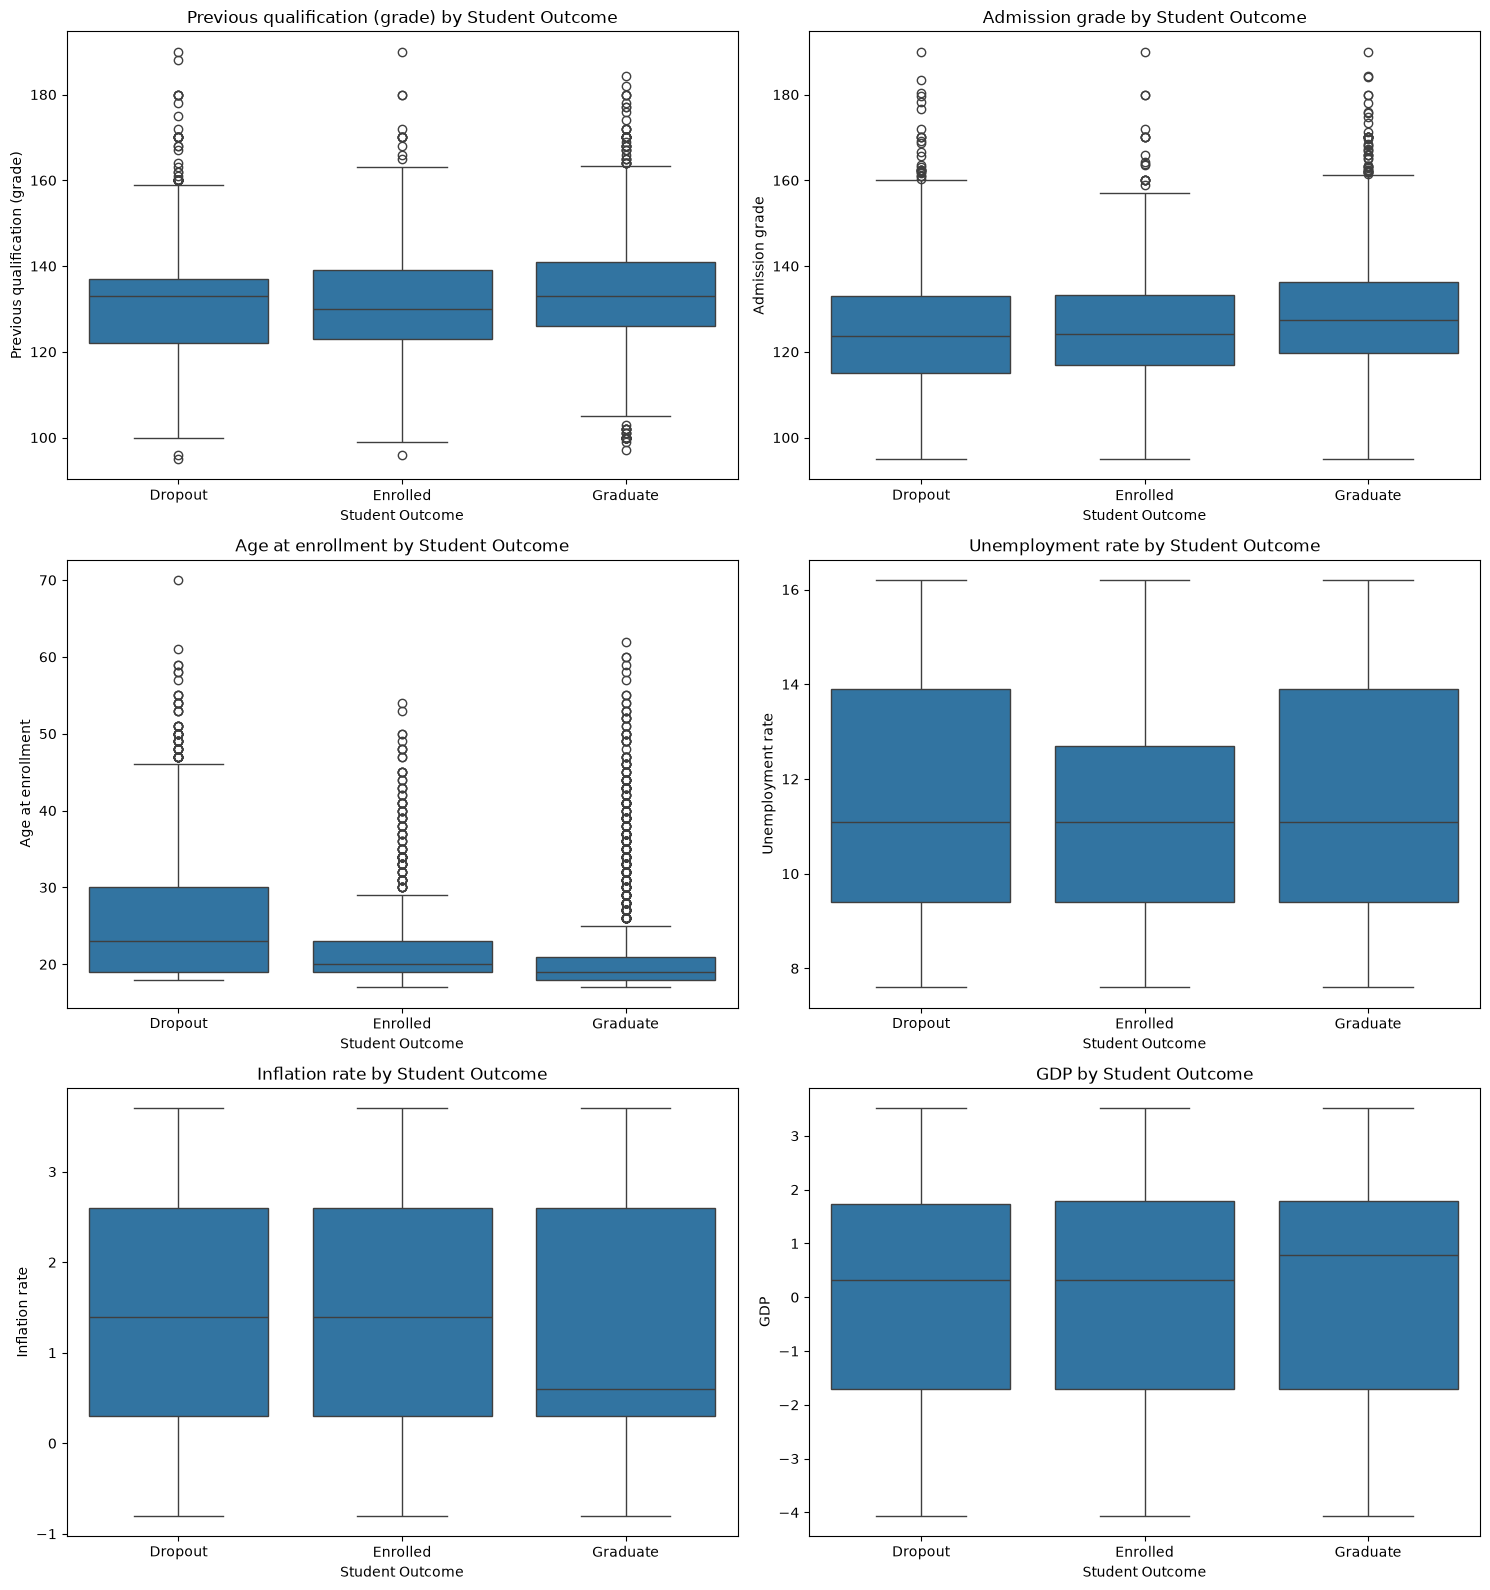

In [29]:
fig, axes = plt.subplots(3, 2, figsize=(15, 16))

for feature, ax in zip(numerical_features, axes.flatten()):

    sns.boxplot(
        data=df,
        x="Target",
        y=feature,
        order=["Dropout", "Enrolled", "Graduate"],
        ax=ax
    )

    ax.set_title(f"{feature} by Student Outcome")
    ax.set_xlabel("Student Outcome")
    ax.set_ylabel(feature)

plt.tight_layout()
plt.show()

In [30]:
# Correlation between numerical admission features

correlation_matrix = df[numerical_features].corr(method="pearson")

display(correlation_matrix.round(3))

,Previous qualification (grade),Admission grade,Age at enrollment,Unemployment rate,Inflation rate,GDP
Previous qualification (grade),1.000,0.580,-0.111,0.045,0.019,-0.053
Admission grade,0.580,1.000,-0.030,0.039,-0.022,-0.020
Age at enrollment,-0.111,-0.030,1.000,0.025,0.025,-0.065
Unemployment rate,0.045,0.039,0.025,1.000,-0.029,-0.335
Inflation rate,0.019,-0.022,0.025,-0.029,1.000,-0.112
GDP,-0.053,-0.020,-0.065,-0.335,-0.112,1.000


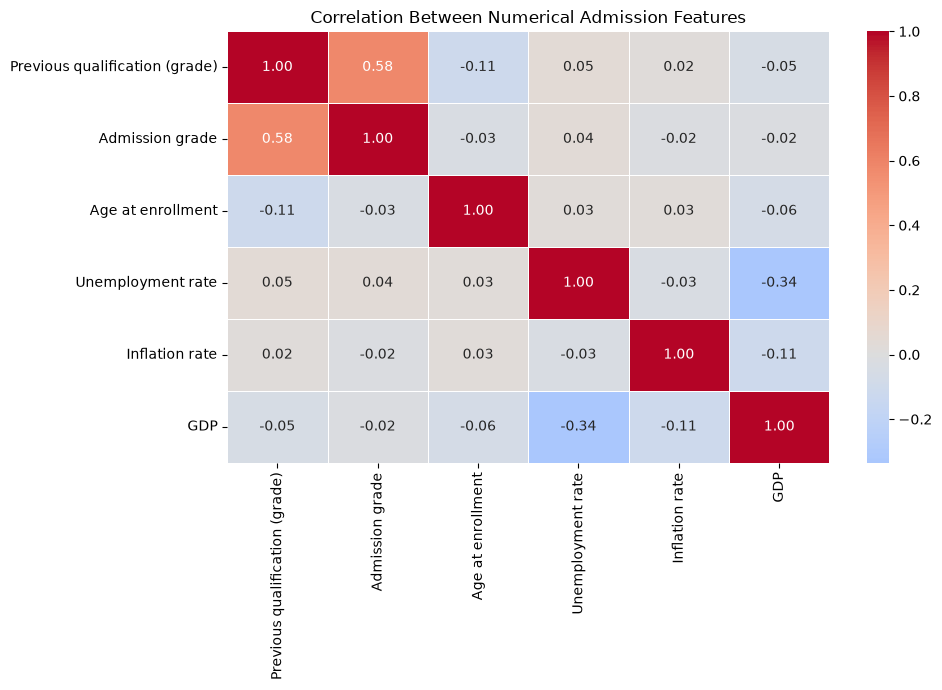

In [31]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Between Numerical Admission Features")
plt.tight_layout()
plt.show()

In [32]:
from scipy.stats import kruskal

statistical_results = []

for feature in numerical_features:

    dropout = df.loc[df["Target"] == "Dropout", feature]
    enrolled = df.loc[df["Target"] == "Enrolled", feature]
    graduate = df.loc[df["Target"] == "Graduate", feature]

    # Kruskal-Wallis test
    h_stat, p_value = kruskal(
        dropout,
        enrolled,
        graduate
    )

    # Effect size: epsilon-squared
    n = len(df)
    k = 3

    epsilon_squared = (
        h_stat - k + 1
    ) / (n - k)

    epsilon_squared = max(0, epsilon_squared)

    statistical_results.append({
        "Feature": feature,
        "H-statistic": h_stat,
        "P-value": p_value,
        "Epsilon-squared": epsilon_squared
    })

kruskal_results = pd.DataFrame(statistical_results)

display(
    kruskal_results.sort_values(
        "Epsilon-squared",
        ascending=False
    ).round(6)
)

,Feature,H-statistic,P-value,Epsilon-squared
2,Age at enrollment,375.106923,0.000000,0.084394
1,Admission grade,73.234687,0.000000,0.016113
0,Previous qualification (grade),63.676925,0.000000,0.013951
5,GDP,14.411002,0.000742,0.002807
3,Unemployment rate,12.880667,0.001596,0.002461
4,Inflation rate,2.437771,0.295559,0.000099


In [33]:
from scipy.stats import mannwhitneyu
from itertools import combinations
import numpy as np
import pandas as pd

top_numerical_features = [
    "Age at enrollment",
    "Admission grade",
    "Previous qualification (grade)"
]

groups = ["Dropout", "Enrolled", "Graduate"]

pairwise_results = []

for feature in top_numerical_features:

    for group1, group2 in combinations(groups, 2):

        values1 = df.loc[df["Target"] == group1, feature]
        values2 = df.loc[df["Target"] == group2, feature]

        statistic, p_value = mannwhitneyu(
            values1,
            values2,
            alternative="two-sided"
        )

        pairwise_results.append({
            "Feature": feature,
            "Comparison": f"{group1} vs {group2}",
            "U-statistic": statistic,
            "P-value": p_value
        })

pairwise_df = pd.DataFrame(pairwise_results)

# Holm correction using NumPy
p_values = pairwise_df["P-value"].to_numpy()

m = len(p_values)
sorted_indices = np.argsort(p_values)
sorted_p = p_values[sorted_indices]

adjusted_sorted = np.maximum.accumulate(
    (m - np.arange(m)) * sorted_p
)

adjusted_sorted = np.minimum(adjusted_sorted, 1.0)

adjusted_p = np.empty(m)
adjusted_p[sorted_indices] = adjusted_sorted

pairwise_df["Adjusted P-value"] = adjusted_p

pairwise_df["Significant"] = (
    pairwise_df["Adjusted P-value"] < 0.05
)

display(
    pairwise_df.sort_values(
        ["Feature", "Adjusted P-value"]
    ).round(6)
)

,Feature,Comparison,U-statistic,P-value,Adjusted P-value,Significant
4,Admission grade,Dropout vs Graduate,1326633.5,0.000000,0.000000,True
5,Admission grade,Enrolled vs Graduate,758776.0,0.000000,0.000000,True
3,Admission grade,Dropout vs Enrolled,546971.0,0.234269,0.468537,False
1,Age at enrollment,Dropout vs Graduate,2147125.0,0.000000,0.000000,True
0,Age at enrollment,Dropout vs Enrolled,716140.5,0.000000,0.000000,True
2,Age at enrollment,Enrolled vs Graduate,998109.0,0.000000,0.000000,True
7,Previous qualification (grade),Dropout vs Graduate,1354748.0,0.000000,0.000000,True
8,Previous qualification (grade),Enrolled vs Graduate,753404.0,0.000000,0.000000,True
6,Previous qualification (grade),Dropout vs Enrolled,568645.5,0.754046,0.754046,False


In [34]:
# Create binary analysis dataset
binary_df = df[
    df["Target"].isin(["Dropout", "Graduate"])
].copy()

# Create binary target
binary_df["target"] = (
    binary_df["Target"] == "Dropout"
).astype(int)

print("Binary dataset shape:", binary_df.shape)

print("\nTarget distribution:")
print(binary_df["Target"].value_counts())

print("\nTarget percentages:")
print(
    (binary_df["Target"].value_counts(normalize=True) * 100)
    .round(2)
)

Binary dataset shape: (3630, 45)

Target distribution:
Target
Graduate    2209
Dropout     1421
Name: count, dtype: int64

Target percentages:
Target
Graduate    60.85
Dropout     39.15
Name: proportion, dtype: float64


In [35]:
binary_numerical_summary = binary_df.groupby(
    "Target"
)[numerical_features].agg(
    ["mean", "median", "std"]
)

display(binary_numerical_summary.round(2))

Previous qualification (grade)               Admission grade         \
                                   mean median    std            mean median   
Target                                                                         
Dropout                          131.11  133.1  12.87          124.96  123.6   
Graduate                         134.08  133.1  13.34          128.79  127.4   

                Age at enrollment              Unemployment rate               \
            std              mean median   std              mean median   std   
Target                                                                          
Dropout   15.13             26.07   23.0  8.70             11.62   11.1  2.77   
Graduate  14.07             21.78   19.0  6.69             11.64   11.1  2.60   

         Inflation rate                GDP               
                   mean median   std  mean median   std  
Target                                                   
Dropout            1.28    1.4  1.40 -0.15   0.32  2.25  
Graduate           1.20    0.6  1.37  0.08   0.79  2.26

In [36]:
from scipy.stats import mannwhitneyu
import numpy as np
import pandas as pd

binary_results = []

dropout_count = (binary_df["Target"] == "Dropout").sum()
graduate_count = (binary_df["Target"] == "Graduate").sum()

for feature in numerical_features:

    dropout = binary_df.loc[
        binary_df["Target"] == "Dropout", feature
    ]

    graduate = binary_df.loc[
        binary_df["Target"] == "Graduate", feature
    ]

    u_stat, p_value = mannwhitneyu(
        dropout,
        graduate,
        alternative="two-sided"
    )

    # Rank-biserial correlation
    rank_biserial = (
        2 * u_stat / (dropout_count * graduate_count)
    ) - 1

    binary_results.append({
        "Feature": feature,
        "U-statistic": u_stat,
        "P-value": p_value,
        "Rank-biserial correlation": rank_biserial
    })

binary_results_df = pd.DataFrame(binary_results)

# Holm correction
p_values = binary_results_df["P-value"].to_numpy()

m = len(p_values)
sorted_indices = np.argsort(p_values)
sorted_p = p_values[sorted_indices]

adjusted_sorted = np.maximum.accumulate(
    (m - np.arange(m)) * sorted_p
)

adjusted_sorted = np.minimum(adjusted_sorted, 1.0)

adjusted_p = np.empty(m)
adjusted_p[sorted_indices] = adjusted_sorted

binary_results_df["Adjusted P-value"] = adjusted_p

binary_results_df["Significant"] = (
    binary_results_df["Adjusted P-value"] < 0.05
)

display(
    binary_results_df.sort_values(
        "Rank-biserial correlation",
        key=lambda x: x.abs(),
        ascending=False
    ).round(6)
)

,Feature,U-statistic,P-value,Rank-biserial correlation,Adjusted P-value,Significant
2,Age at enrollment,2147125.0,0.000000,0.368036,0.000000,True
1,Admission grade,1326633.5,0.000000,-0.154738,0.000000,True
0,Previous qualification (grade),1354748.0,0.000000,-0.136825,0.000000,True
5,GDP,1455424.5,0.000198,-0.072679,0.000595,True
4,Inflation rate,1616022.5,0.127949,0.029645,0.255899,False
3,Unemployment rate,1553928.5,0.611615,-0.009918,0.611615,False


In [37]:
from scipy.stats import chi2_contingency
import numpy as np
import pandas as pd

# Combine nominal and binary categorical features
categorical_features_binary = (
    categorical_features + binary_features
)

categorical_results = []

for feature in categorical_features_binary:

    contingency = pd.crosstab(
        binary_df[feature],
        binary_df["Target"]
    )

    chi2, p_value, dof, expected = chi2_contingency(
        contingency
    )

    # Bias-corrected Cramer's V
    n = contingency.to_numpy().sum()
    rows, cols = contingency.shape

    phi2 = chi2 / n

    phi2_corrected = max(
        0,
        phi2 - ((cols - 1) * (rows - 1)) / (n - 1)
    )

    rows_corrected = (
        rows - ((rows - 1) ** 2) / (n - 1)
    )

    cols_corrected = (
        cols - ((cols - 1) ** 2) / (n - 1)
    )

    denominator = min(
        rows_corrected - 1,
        cols_corrected - 1
    )

    cramers_v = (
        np.sqrt(phi2_corrected / denominator)
        if denominator > 0 else np.nan
    )

    categorical_results.append({
        "Feature": feature,
        "Chi-square": chi2,
        "P-value": p_value,
        "Cramer's V": cramers_v,
        "Minimum expected frequency": expected.min(),
        "Expected frequencies below 5 (%)": (
            (expected < 5).sum() / expected.size
        ) * 100
    })

categorical_results_df = pd.DataFrame(
    categorical_results
)

display(
    categorical_results_df.sort_values(
        "Cramer's V",
        ascending=False
    ).round(4)
)

,Feature,Chi-square,P-value,Cramer's V,Minimum expected frequency,Expected frequencies below 5 (%)
13,Tuition fees up to date,706.9551,0.0000,0.4411,190.2496,0.0000
2,Course,442.9480,0.0000,0.3430,3.5231,2.9412
1,Application mode,392.0659,0.0000,0.3215,0.3915,30.5556
15,Scholarship holder,354.2193,0.0000,0.3120,379.3248,0.0000
12,Debtor,257.4596,0.0000,0.2658,161.6730,0.0000
14,Gender,229.3515,0.0000,0.2508,488.9336,0.0000
3,Previous qualification,150.5990,0.0000,0.1926,0.3915,44.1176
5,Mother's qualification,143.0143,0.0000,0.1780,0.3915,65.5172
6,Father's qualification,147.8617,0.0000,0.1779,0.3915,66.1765
7,Mother's occupation,138.2351,0.0000,0.1743,0.3915,55.1724


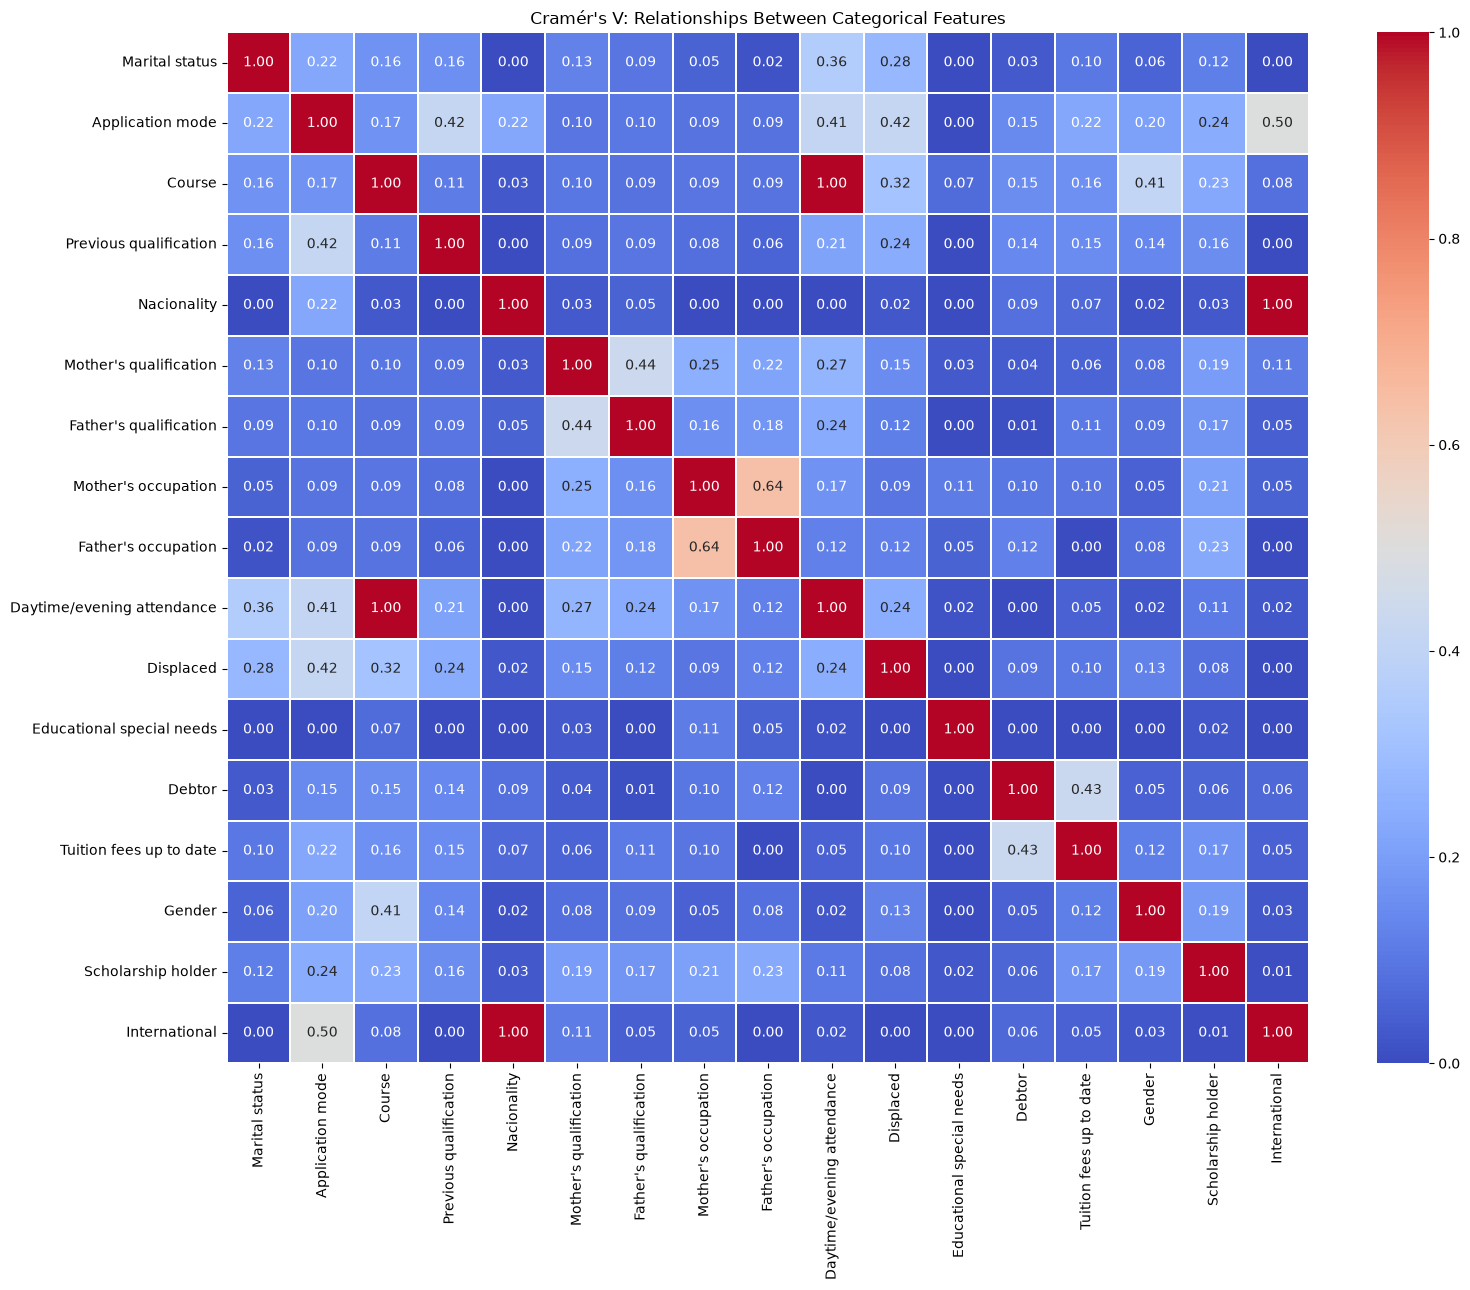

In [38]:
from scipy.stats import chi2_contingency
import numpy as np
import pandas as pd

categorical_features_binary = (
    categorical_features + binary_features
)

association_matrix = pd.DataFrame(
    np.zeros((
        len(categorical_features_binary),
        len(categorical_features_binary)
    )),
    index=categorical_features_binary,
    columns=categorical_features_binary
)

for feature1 in categorical_features_binary:

    for feature2 in categorical_features_binary:

        if feature1 == feature2:
            association_matrix.loc[feature1, feature2] = 1.0
            continue

        contingency = pd.crosstab(
            binary_df[feature1],
            binary_df[feature2]
        )

        chi2 = chi2_contingency(contingency)[0]

        n = contingency.to_numpy().sum()
        rows, cols = contingency.shape

        phi2 = chi2 / n

        phi2_corrected = max(
            0,
            phi2 - ((cols - 1) * (rows - 1)) / (n - 1)
        )

        rows_corrected = (
            rows - ((rows - 1) ** 2) / (n - 1)
        )

        cols_corrected = (
            cols - ((cols - 1) ** 2) / (n - 1)
        )

        denominator = min(
            rows_corrected - 1,
            cols_corrected - 1
        )

        cramers_v = (
            np.sqrt(phi2_corrected / denominator)
            if denominator > 0 else np.nan
        )

        association_matrix.loc[
            feature1, feature2
        ] = cramers_v

plt.figure(figsize=(16, 13))

sns.heatmap(
    association_matrix,
    cmap="coolwarm",
    vmin=0,
    vmax=1,
    annot=True,
    fmt=".2f",
    linewidths=0.3
)

plt.title("Cramér's V: Relationships Between Categorical Features")
plt.tight_layout()
plt.show()

In [39]:
# Pair 1: Course and attendance mode

print("COURSE vs DAYTIME/EVENING ATTENDANCE")

display(
    pd.crosstab(
        binary_df["Course"],
        binary_df["Daytime/evening attendance"],
        margins=True
    )
)

print("\nNumber of attendance modes per course:")

display(
    binary_df.groupby("Course")[
        "Daytime/evening attendance"
    ].nunique().value_counts()
)


# Pair 2: Nationality and International

print("\nNATIONALITY vs INTERNATIONAL")

display(
    pd.crosstab(
        binary_df["Nacionality"],
        binary_df["International"],
        margins=True
    )
)

print("\nNumber of International values per nationality:")

display(
    binary_df.groupby("Nacionality")[
        "International"
    ].nunique().value_counts()
)

COURSE vs DAYTIME/EVENING ATTENDANCE


Daytime/evening attendance,0,1,All
Course,,,
33,0,9,9
171,0,178,178
8014,194,0,194
9003,0,173,173
9070,0,184,184
9085,0,262,262
9119,0,106,106
9130,0,120,120
9147,0,272,272



Number of attendance modes per course:


Daytime/evening attendance
1    17
Name: count, dtype: int64


NATIONALITY vs INTERNATIONAL


International,0,1,All
Nacionality,,,
1,3544,0,3544
2,0,2,2
6,0,8,8
11,0,3,3
13,0,1,1
14,0,1,1
17,0,1,1
21,0,1,1
22,0,12,12



Number of International values per nationality:


International
1    19
Name: count, dtype: int64

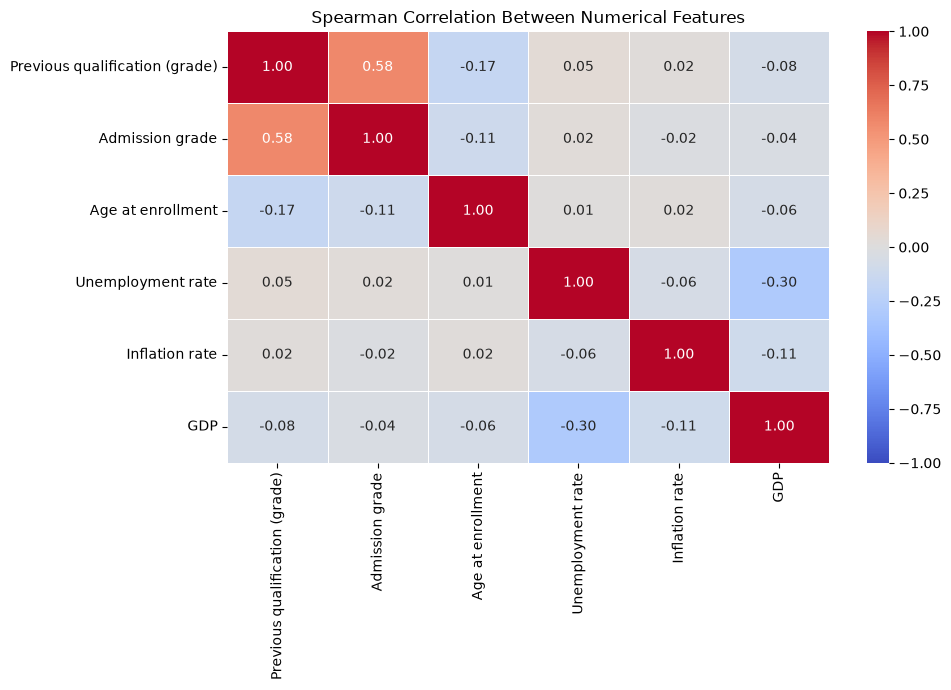

In [40]:
numerical_corr = binary_df[numerical_features].corr(
    method="spearman"
)

plt.figure(figsize=(10, 7))

sns.heatmap(
    numerical_corr,
    annot=True,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    fmt=".2f",
    linewidths=0.5
)

plt.title("Spearman Correlation Between Numerical Features")
plt.tight_layout()
plt.show()


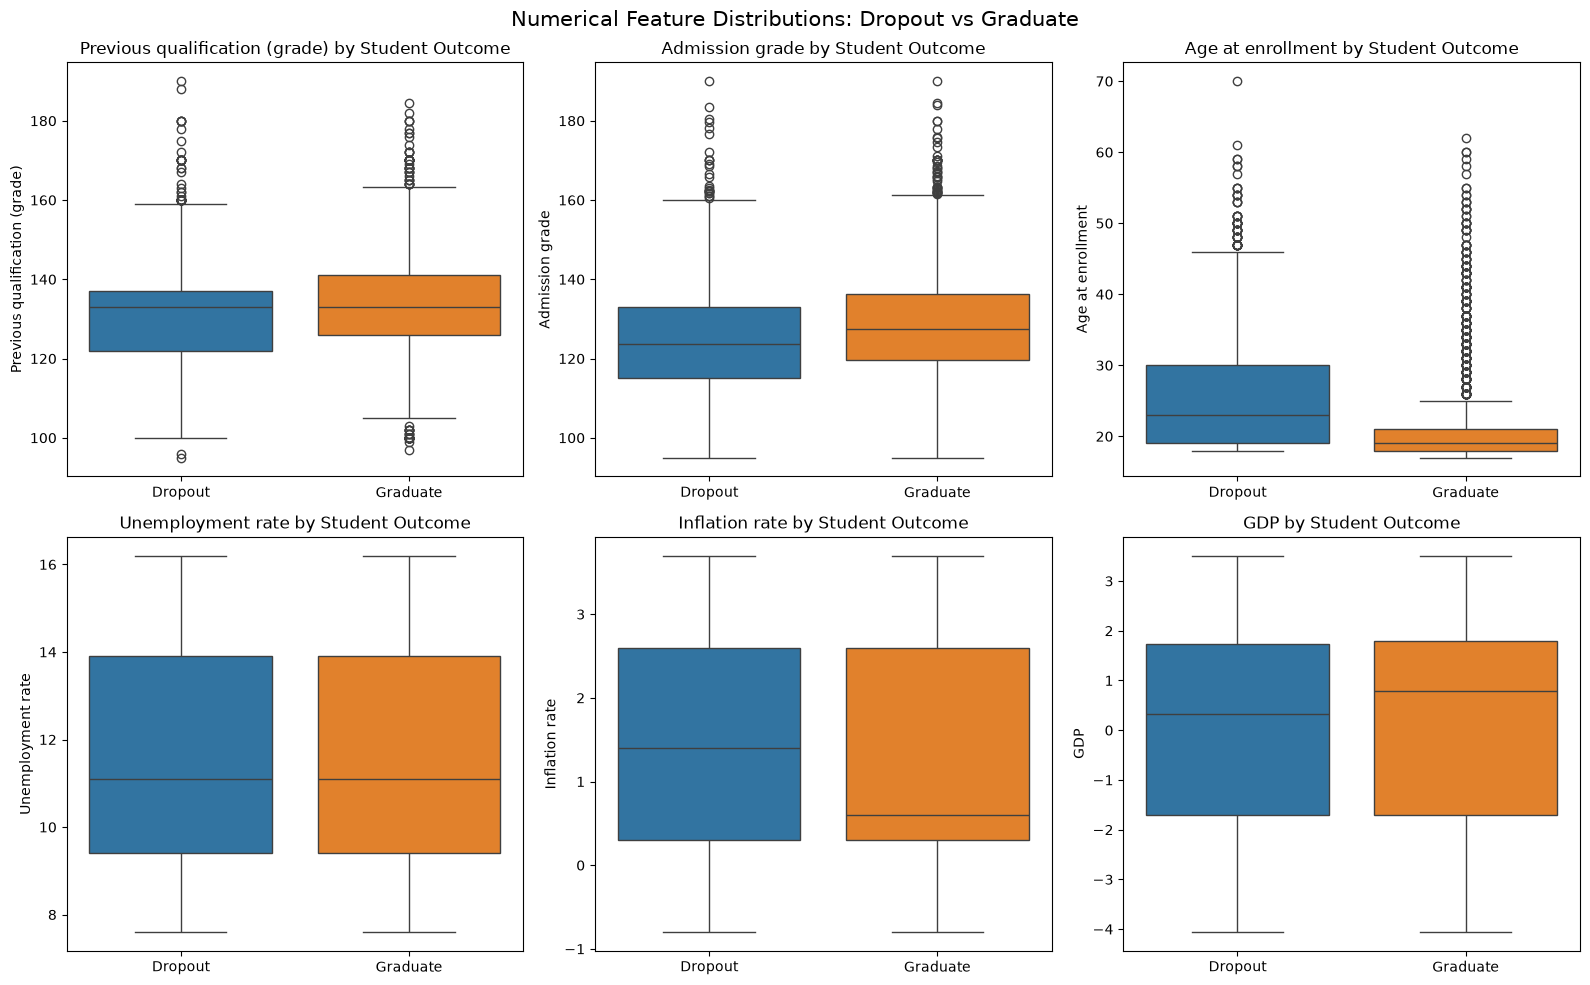

In [41]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))

for feature, ax in zip(numerical_features, axes.flatten()):

    sns.boxplot(
        data=binary_df,
        x="Target",
        y=feature,
        ax=ax,
        hue="Target",
        legend=False
    )

    ax.set_title(f"{feature} by Student Outcome")
    ax.set_xlabel("")
    ax.set_ylabel(feature)

plt.suptitle(
    "Numerical Feature Distributions: Dropout vs Graduate",
    fontsize=15
)

plt.tight_layout()
plt.show()


In [42]:
print("SEMESTER FEATURES:")

for col in semester_features:
    print(col)

SEMESTER FEATURES:
Curricular units 1st sem (credited)
Curricular units 1st sem (enrolled)
Curricular units 1st sem (evaluations)
Curricular units 1st sem (approved)
Curricular units 1st sem (grade)
Curricular units 1st sem (without evaluations)
Curricular units 2nd sem (credited)
Curricular units 2nd sem (enrolled)
Curricular units 2nd sem (evaluations)
Curricular units 2nd sem (approved)
Curricular units 2nd sem (grade)
Curricular units 2nd sem (without evaluations)


In [43]:
# Group semester features by semester

semester_1_features = [
    col for col in semester_features
    if "1st sem" in col
]

semester_2_features = [
    col for col in semester_features
    if "2nd sem" in col
]

# Compare average values across student outcomes

print("FIRST SEMESTER: AVERAGE VALUES")

display(
    df.groupby("Target")[semester_1_features]
    .mean()
    .round(2)
    .T
)

print("\nSECOND SEMESTER: AVERAGE VALUES")

display(
    df.groupby("Target")[semester_2_features]
    .mean()
    .round(2)
    .T
)

FIRST SEMESTER: AVERAGE VALUES


Target,Dropout,Enrolled,Graduate
Curricular units 1st sem (credited),0.61,0.51,0.85
Curricular units 1st sem (enrolled),5.82,5.96,6.67
Curricular units 1st sem (evaluations),7.75,9.34,8.28
Curricular units 1st sem (approved),2.55,4.32,6.23
Curricular units 1st sem (grade),7.26,11.13,12.64
Curricular units 1st sem (without evaluations),0.19,0.18,0.09



SECOND SEMESTER: AVERAGE VALUES


Target,Dropout,Enrolled,Graduate
Curricular units 2nd sem (credited),0.45,0.36,0.67
Curricular units 2nd sem (enrolled),5.78,5.94,6.63
Curricular units 2nd sem (evaluations),7.17,9.44,8.14
Curricular units 2nd sem (approved),1.94,4.06,6.18
Curricular units 2nd sem (grade),5.90,11.12,12.70
Curricular units 2nd sem (without evaluations),0.24,0.19,0.08


In [44]:
# Calculate individual academic performance ratios

for semester in ["1st sem", "2nd sem"]:

    enrolled_col = f"Curricular units {semester} (enrolled)"
    approved_col = f"Curricular units {semester} (approved)"
    evaluations_col = f"Curricular units {semester} (evaluations)"

    # Approved units / enrolled units
    df[f"{semester} approval rate"] = (
        df[approved_col] / df[enrolled_col].replace(0, np.nan)
    )

    # Evaluations / enrolled units
    df[f"{semester} evaluation rate"] = (
        df[evaluations_col] / df[enrolled_col].replace(0, np.nan)
    )


# Compare average individual rates across outcomes

rate_columns = [
    "1st sem approval rate",
    "2nd sem approval rate",
    "1st sem evaluation rate",
    "2nd sem evaluation rate"
]

display(
    (df.groupby("Target")[rate_columns].mean() * 100)
    .round(2)
)

,1st sem approval rate,2nd sem approval rate,1st sem evaluation rate,2nd sem evaluation rate
Target,,,,
Dropout,40.60,31.01,134.53,125.39
Enrolled,71.35,67.31,159.66,161.60
Graduate,93.50,93.21,125.47,124.46


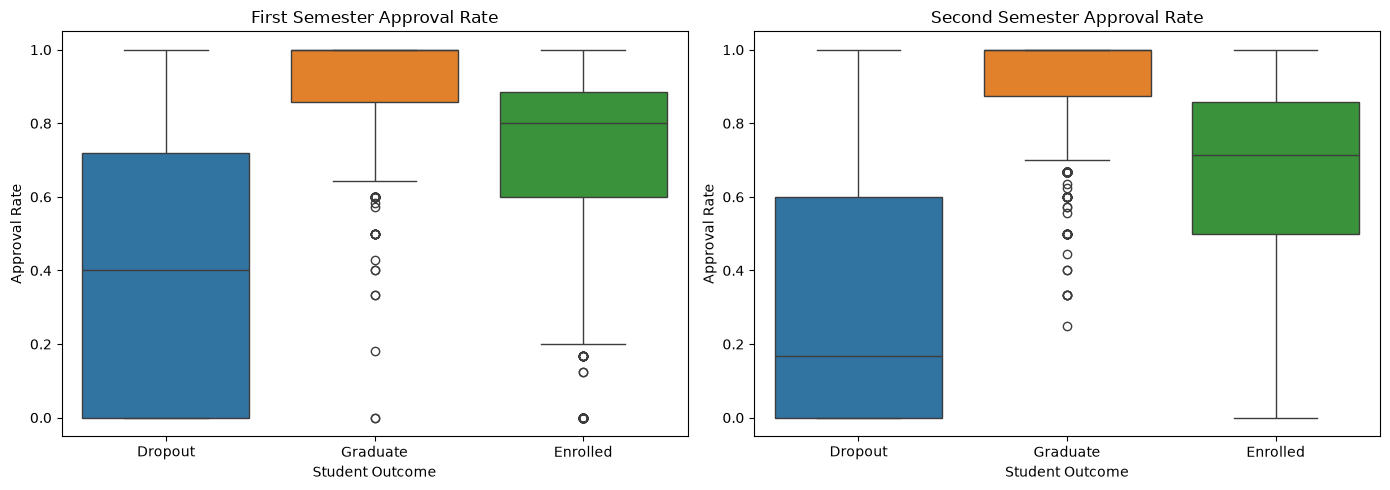

In [45]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(
    data=df,
    x="Target",
    y="1st sem approval rate",
    hue="Target",
    legend=False,
    ax=axes[0]
)

axes[0].set_title("First Semester Approval Rate")
axes[0].set_ylabel("Approval Rate")
axes[0].set_xlabel("Student Outcome")

sns.boxplot(
    data=df,
    x="Target",
    y="2nd sem approval rate",
    hue="Target",
    legend=False,
    ax=axes[1]
)

axes[1].set_title("Second Semester Approval Rate")
axes[1].set_ylabel("Approval Rate")
axes[1].set_xlabel("Student Outcome")

plt.tight_layout()
plt.show()

In [46]:
from scipy.stats import kruskal
from itertools import combinations

approval_features = [
    "1st sem approval rate",
    "2nd sem approval rate"
]

targets = ["Dropout", "Enrolled", "Graduate"]

# Overall comparison
for feature in approval_features:

    groups = [
        df.loc[df["Target"] == target, feature].dropna()
        for target in targets
    ]

    h_stat, p_value = kruskal(*groups)

    n = sum(len(group) for group in groups)
    k = len(groups)

    epsilon_squared = (
        h_stat - k + 1
    ) / (n - k)

    print(f"\n{feature}")
    print(f"Kruskal-Wallis H: {h_stat:.4f}")
    print(f"P-value: {p_value:.8f}")
    print(f"Epsilon-squared: {epsilon_squared:.4f}")


1st sem approval rate
Kruskal-Wallis H: 1941.0841
P-value: 0.00000000
Epsilon-squared: 0.4572

2nd sem approval rate
Kruskal-Wallis H: 2324.5156
P-value: 0.00000000
Epsilon-squared: 0.5476


In [48]:
from scipy.stats import mannwhitneyu
from itertools import combinations
import pandas as pd
import numpy as np

approval_features = [
    "1st sem approval rate",
    "2nd sem approval rate"
]

targets = ["Dropout", "Enrolled", "Graduate"]

pairwise_results = []

for feature in approval_features:

    for group1, group2 in combinations(targets, 2):

        values1 = df.loc[
            df["Target"] == group1, feature
        ].dropna()

        values2 = df.loc[
            df["Target"] == group2, feature
        ].dropna()

        u_stat, p_value = mannwhitneyu(
            values1,
            values2,
            alternative="two-sided"
        )

        pairwise_results.append({
            "Feature": feature,
            "Comparison": f"{group1} vs {group2}",
            "U-statistic": u_stat,
            "P-value": p_value
        })


results_df = pd.DataFrame(pairwise_results)


# Manual Holm-Bonferroni correction
p_values = results_df["P-value"].to_numpy()

n = len(p_values)

sorted_indices = np.argsort(p_values)
sorted_p = p_values[sorted_indices]

adjusted_sorted = np.maximum.accumulate(
    (n - np.arange(n)) * sorted_p
)

adjusted_sorted = np.minimum(adjusted_sorted, 1.0)

adjusted_p = np.empty(n)
adjusted_p[sorted_indices] = adjusted_sorted

results_df["Adjusted P-value"] = adjusted_p

results_df["Significant"] = (
    results_df["Adjusted P-value"] < 0.05
)

display(results_df.round(8))

,Feature,Comparison,U-statistic,P-value,Adjusted P-value,Significant
0,1st sem approval rate,Dropout vs Enrolled,275268.0,0.0,0.0,True
1,1st sem approval rate,Dropout vs Graduate,288122.0,0.0,0.0,True
2,1st sem approval rate,Enrolled vs Graduate,353374.0,0.0,0.0,True
3,2nd sem approval rate,Dropout vs Enrolled,230751.5,0.0,0.0,True
4,2nd sem approval rate,Dropout vs Graduate,195787.5,0.0,0.0,True
5,2nd sem approval rate,Enrolled vs Graduate,278921.0,0.0,0.0,True


In [49]:
for semester in ["1st sem", "2nd sem"]:

    enrolled = f"Curricular units {semester} (enrolled)"
    approved = f"Curricular units {semester} (approved)"

    rate = (
        df[approved] /
        df[enrolled].replace(0, np.nan)
    )

    df[f"{semester} performance category"] = pd.cut(
        rate,
        bins=[-np.inf, 0, 0.5, 0.999999, np.inf],
        labels=[
            "Zero approved",
            "Below 50%",
            "50% to below 100%",
            "100% approved"
        ]
    )

    print(f"\n{semester.upper()}")

    display(
        pd.crosstab(
            df["Target"],
            df[f"{semester} performance category"],
            normalize="index"
        ).mul(100).round(2)
    )


1ST SEM


1st sem performance category,Zero approved,Below 50%,50% to below 100%,100% approved
Target,,,,
Dropout,36.68,22.17,29.91,11.24
Enrolled,5.61,14.36,56.27,23.76
Graduate,0.09,0.70,33.83,65.37



2ND SEM


2nd sem performance category,Zero approved,Below 50%,50% to below 100%,100% approved
Target,,,,
Dropout,48.36,21.88,22.77,6.99
Enrolled,5.22,20.50,58.09,16.19
Graduate,0.00,1.31,34.44,64.25


,1st sem approval rate,2nd sem approval rate
1st sem approval rate,1.000,0.773
2nd sem approval rate,0.773,1.000


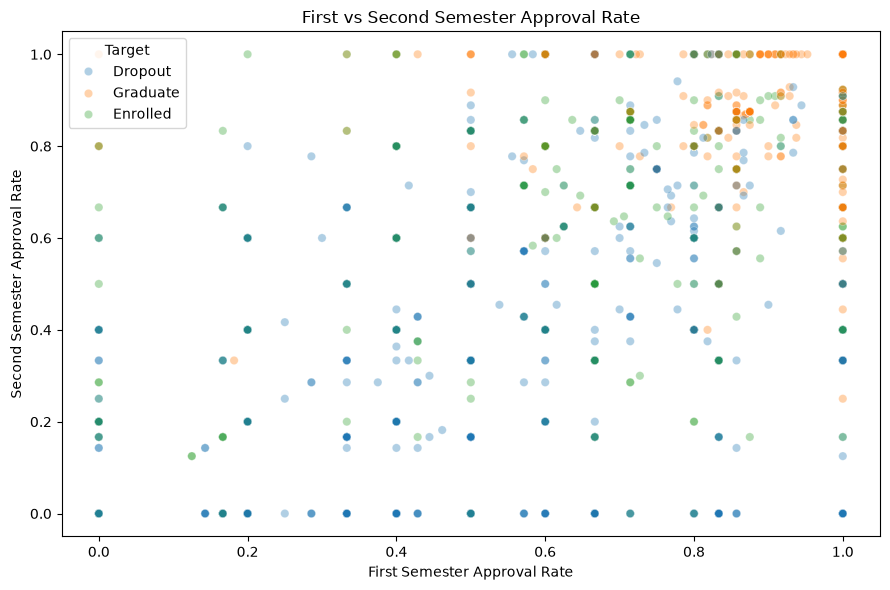

In [50]:
# Correlation between first and second semester approval rates

approval_correlation = df[
    ["1st sem approval rate", "2nd sem approval rate"]
].corr(method="spearman")

display(approval_correlation.round(4))

# Visualize the relationship

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="1st sem approval rate",
    y="2nd sem approval rate",
    hue="Target",
    alpha=0.35
)

plt.title(
    "First vs Second Semester Approval Rate"
)

plt.xlabel("First Semester Approval Rate")
plt.ylabel("Second Semester Approval Rate")

plt.tight_layout()
plt.show()

,Group,Spearman Correlation,P-value,Sample Size
0,All Students,0.7730,0.0,4244
1,Dropout,0.7983,0.0,1344
2,Enrolled,0.4931,0.0,766
3,Graduate,0.4469,0.0,2134


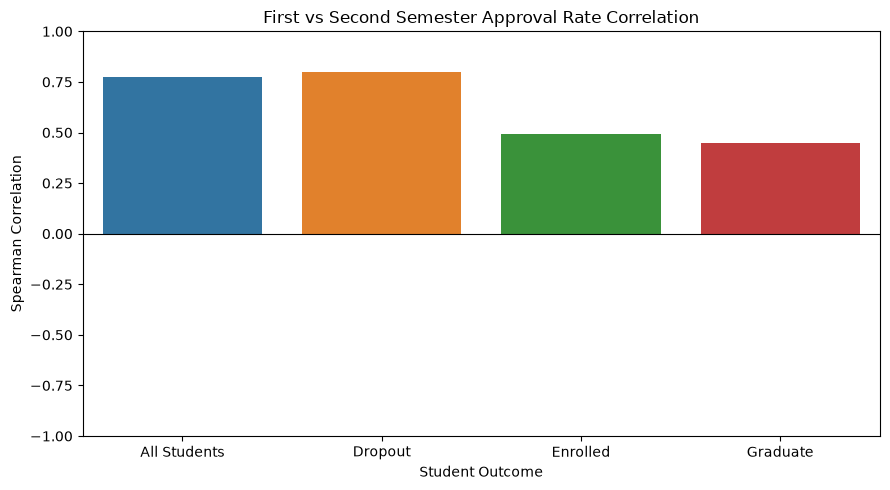

In [51]:
from scipy.stats import spearmanr
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

first = "1st sem approval rate"
second = "2nd sem approval rate"

# Calculate correlations overall and within each outcome
correlation_results = []

groups = ["All Students", "Dropout", "Enrolled", "Graduate"]

for group in groups:

    if group == "All Students":
        subset = df[[first, second]].dropna()
    else:
        subset = df.loc[
            df["Target"] == group,
            [first, second]
        ].dropna()

    rho, p_value = spearmanr(
        subset[first],
        subset[second]
    )

    correlation_results.append({
        "Group": group,
        "Spearman Correlation": rho,
        "P-value": p_value,
        "Sample Size": len(subset)
    })

correlation_df = pd.DataFrame(correlation_results)

display(correlation_df.round(4))


# Visualize correlation strength
plt.figure(figsize=(9, 5))

sns.barplot(
    data=correlation_df,
    x="Group",
    y="Spearman Correlation",
    hue="Group",
    legend=False
)

plt.axhline(0, color="black", linewidth=0.8)

plt.ylim(-1, 1)
plt.title(
    "First vs Second Semester Approval Rate Correlation"
)
plt.xlabel("Student Outcome")
plt.ylabel("Spearman Correlation")

plt.tight_layout()
plt.show()

In [52]:
# Original admission-time feature candidates
candidate_features = (
    numerical_features
    + ordinal_features
    + binary_features
    + categorical_features
)

# Remove deterministic redundant features
features_reduced = [
    col for col in candidate_features
    if col not in [
        "Daytime/evening attendance",
        "Nacionality"
    ]
]

print("Original feature count:", len(candidate_features))
print("Reduced feature count:", len(features_reduced))

print("\nFeatures removed:")
print("Daytime/evening attendance")
print("Nacionality")

print("\nRemaining features:")
for i, feature in enumerate(features_reduced, 1):
    print(f"{i}. {feature}")

Original feature count: 24
Reduced feature count: 22

Features removed:
Daytime/evening attendance
Nacionality

Remaining features:
1. Previous qualification (grade)
2. Admission grade
3. Age at enrollment
4. Unemployment rate
5. Inflation rate
6. GDP
7. Application order
8. Displaced
9. Educational special needs
10. Debtor
11. Tuition fees up to date
12. Gender
13. Scholarship holder
14. International
15. Marital status
16. Application mode
17. Course
18. Previous qualification
19. Mother's qualification
20. Father's qualification
21. Mother's occupation
22. Father's occupation


Training set: (2904, 22)
Testing set: (726, 22)

Training target distribution:
Target
Graduate    1767
Dropout     1137
Name: count, dtype: int64

Testing target distribution:
Target
Graduate    442
Dropout     284
Name: count, dtype: int64


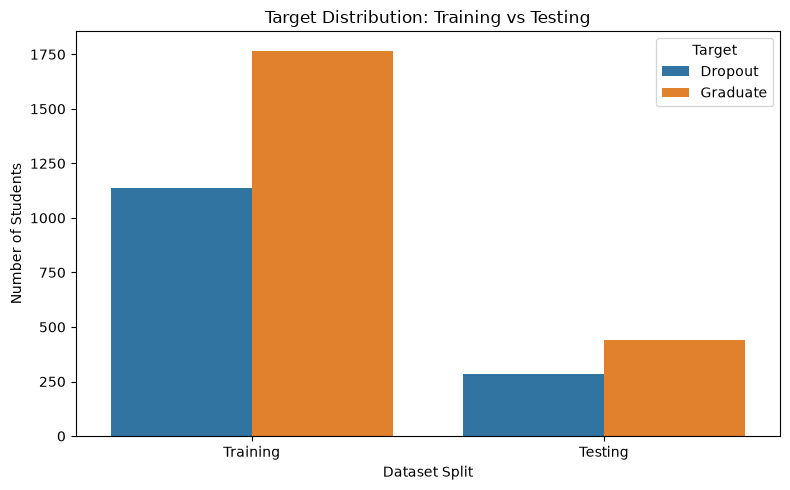

In [53]:

from sklearn.model_selection import train_test_split
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Prepare the binary classification dataset
X_fs = binary_df[features_reduced].copy()

y_fs = binary_df["Target"].map({
    "Graduate": 0,
    "Dropout": 1
})

# Verify target encoding
assert y_fs.notna().all(), "Unexpected target values found!"

# Create a stratified 80/20 split
X_train_fs, X_test_fs, y_train_fs, y_test_fs = train_test_split(
    X_fs,
    y_fs,
    test_size=0.20,
    random_state=42,
    stratify=y_fs
)

# Display dataset dimensions
print("Training set:", X_train_fs.shape)
print("Testing set:", X_test_fs.shape)

print("\nTraining target distribution:")
print(y_train_fs.value_counts().rename(index={
    0: "Graduate",
    1: "Dropout"
}))

print("\nTesting target distribution:")
print(y_test_fs.value_counts().rename(index={
    0: "Graduate",
    1: "Dropout"
}))

# Visualize class distribution across the splits
split_distribution = pd.concat([
    pd.DataFrame({
        "Dataset": "Training",
        "Target": y_train_fs.map({0: "Graduate", 1: "Dropout"})
    }),
    pd.DataFrame({
        "Dataset": "Testing",
        "Target": y_test_fs.map({0: "Graduate", 1: "Dropout"})
    })
], ignore_index=True)

plt.figure(figsize=(8, 5))

sns.countplot(
    data=split_distribution,
    x="Dataset",
    hue="Target"
)

plt.title("Target Distribution: Training vs Testing")
plt.xlabel("Dataset Split")
plt.ylabel("Number of Students")
plt.tight_layout()
plt.show()


Missing values in training features: 0


,Feature,Mutual Information
0,Tuition fees up to date,0.1033
1,Course,0.0623
2,Scholarship holder,0.0575
3,Application mode,0.0555
4,Age at enrollment,0.0505
5,Previous qualification (grade),0.0404
6,Debtor,0.0360
7,Gender,0.0325
8,Admission grade,0.0302
9,Mother's occupation,0.0222


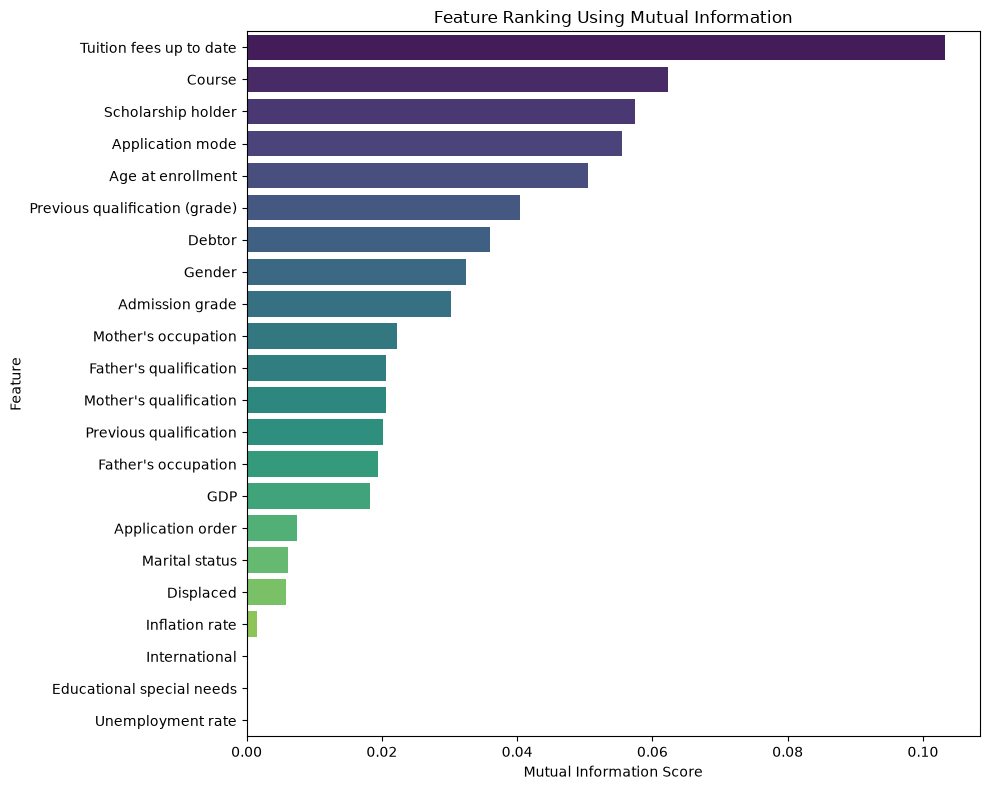

In [54]:

from sklearn.feature_selection import mutual_info_classif
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Identify discrete and continuous features
# All non-numerical predictors are treated as discrete categories
discrete_mask = [
    feature not in numerical_features
    for feature in features_reduced
]

# Check for missing values before calculation
print("Missing values in training features:",
      X_train_fs.isnull().sum().sum())

# Calculate Mutual Information using training data only
mi_scores = mutual_info_classif(
    X_train_fs,
    y_train_fs,
    discrete_features=discrete_mask,
    random_state=42
)

# Create a ranked results table
mi_results = pd.DataFrame({
    "Feature": features_reduced,
    "Mutual Information": mi_scores
}).sort_values(
    by="Mutual Information",
    ascending=False
).reset_index(drop=True)

display(mi_results.round(4))

# Visualize feature importance ranking
plt.figure(figsize=(10, 8))

sns.barplot(
    data=mi_results,
    x="Mutual Information",
    y="Feature",
    hue="Feature",
    palette="viridis",
    legend=False
)

plt.title("Feature Ranking Using Mutual Information")
plt.xlabel("Mutual Information Score")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()


Validation ROC-AUC: 0.8141 (Accuracy; ROC-AUC calculated below)
Validation ROC-AUC: 0.8526
Validation PR-AUC: 0.8315


,Feature,Importance Mean,Importance Std
0,Tuition fees up to date,0.1527,0.0154
1,Course,0.0657,0.0095
2,Scholarship holder,0.0386,0.0052
3,Application mode,0.0342,0.0052
4,Debtor,0.0126,0.0025
5,Gender,0.0095,0.0032
6,Admission grade,0.0093,0.0036
7,Mother's occupation,0.0074,0.0030
8,Father's occupation,0.0051,0.0033
9,Mother's qualification,0.0032,0.0030


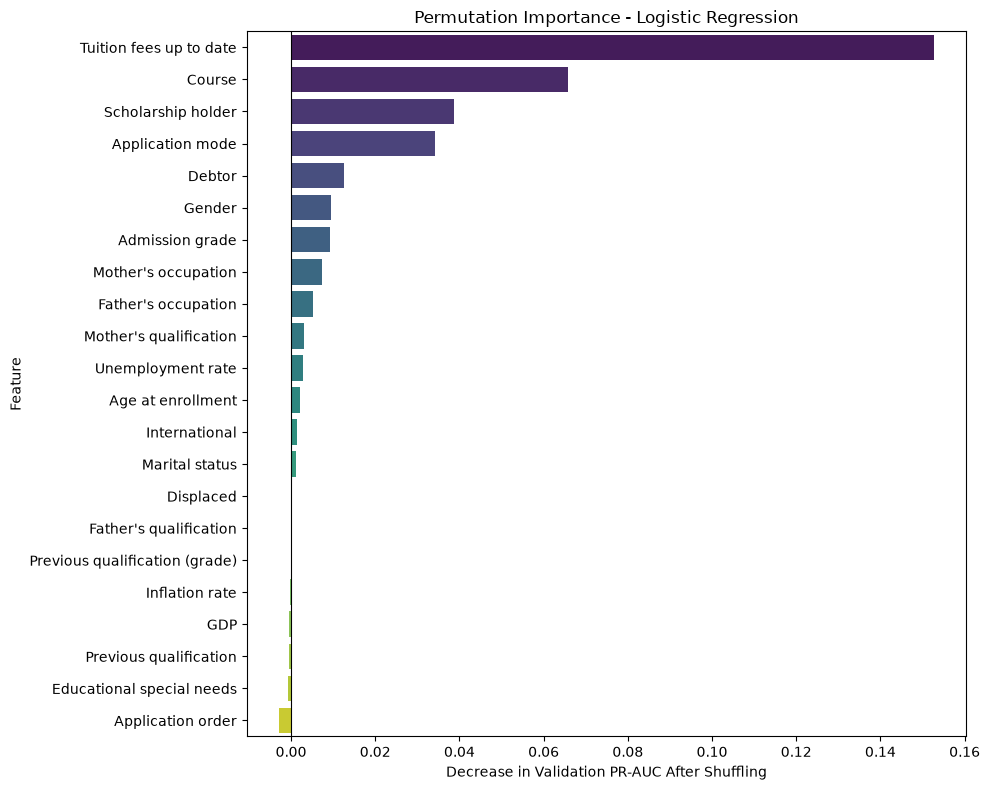

In [55]:

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.inspection import permutation_importance

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Split training data into model-training and validation sets
X_model_train, X_val, y_model_train, y_val = train_test_split(
    X_train_fs,
    y_train_fs,
    test_size=0.20,
    random_state=42,
    stratify=y_train_fs
)

# Separate numerical and categorical features
numerical_fs = [
    col for col in features_reduced
    if col in numerical_features
]

categorical_fs = [
    col for col in features_reduced
    if col not in numerical_fs
]

# Preprocessing
preprocessor = ColumnTransformer([
    ("num", StandardScaler(), numerical_fs),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_fs)
])

# Logistic Regression pipeline
lr_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=2000))
])

# Train using the internal training split
lr_pipeline.fit(X_model_train, y_model_train)

# Evaluate on validation data
print("Validation ROC-AUC:",
      round(lr_pipeline.score(X_val, y_val), 4),
      "(Accuracy; ROC-AUC calculated below)")

from sklearn.metrics import roc_auc_score, average_precision_score

val_probabilities = lr_pipeline.predict_proba(X_val)[:, 1]

print("Validation ROC-AUC:",
      round(roc_auc_score(y_val, val_probabilities), 4))

print("Validation PR-AUC:",
      round(average_precision_score(y_val, val_probabilities), 4))

# Calculate permutation importance on original feature columns
perm_results = permutation_importance(
    lr_pipeline,
    X_val,
    y_val,
    scoring="average_precision",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "Feature": features_reduced,
    "Importance Mean": perm_results.importances_mean,
    "Importance Std": perm_results.importances_std
}).sort_values(
    "Importance Mean",
    ascending=False
).reset_index(drop=True)

display(importance_df.round(4))

# Visualize feature importance
plt.figure(figsize=(10, 8))

sns.barplot(
    data=importance_df,
    x="Importance Mean",
    y="Feature",
    hue="Feature",
    palette="viridis",
    legend=False
)

plt.axvline(0, color="black", linewidth=0.8)
plt.title("Permutation Importance - Logistic Regression")
plt.xlabel("Decrease in Validation PR-AUC After Shuffling")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()


Random Forest Validation Results
Accuracy: 0.7797
ROC-AUC: 0.8402
PR-AUC: 0.8154


,Feature,Importance Mean,Importance Std
0,Tuition fees up to date,0.1698,0.0162
1,Scholarship holder,0.0432,0.0054
2,Course,0.0292,0.0041
3,Debtor,0.0153,0.0026
4,Age at enrollment,0.0138,0.0042
5,Gender,0.0123,0.0034
6,Previous qualification (grade),0.0056,0.0032
7,Application mode,0.0031,0.0024
8,Displaced,0.0019,0.0020
9,Admission grade,0.0018,0.0026


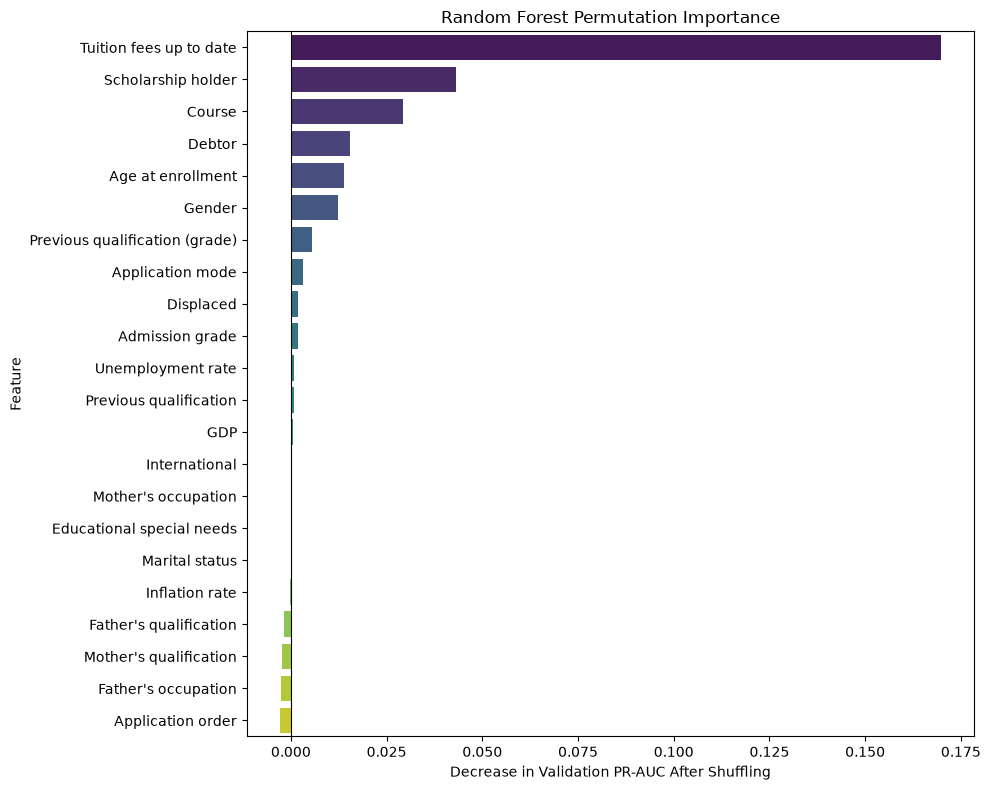

In [56]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    average_precision_score
)
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Random Forest does not require numerical scaling
rf_preprocessor = ColumnTransformer([
    ("num", "passthrough", numerical_fs),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_fs)
])

rf_pipeline = Pipeline([
    ("preprocessor", rf_preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=400,
        random_state=42,
        class_weight="balanced",
        min_samples_leaf=2,
        n_jobs=-1
    ))
])

# Train using the same internal training split
rf_pipeline.fit(X_model_train, y_model_train)

# Validation predictions
rf_predictions = rf_pipeline.predict(X_val)
rf_probabilities = rf_pipeline.predict_proba(X_val)[:, 1]

print("Random Forest Validation Results")
print("Accuracy:",
      round(accuracy_score(y_val, rf_predictions), 4))
print("ROC-AUC:",
      round(roc_auc_score(y_val, rf_probabilities), 4))
print("PR-AUC:",
      round(average_precision_score(y_val, rf_probabilities), 4))

# Permutation importance on original feature columns
rf_perm = permutation_importance(
    rf_pipeline,
    X_val,
    y_val,
    scoring="average_precision",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

rf_importance_df = pd.DataFrame({
    "Feature": features_reduced,
    "Importance Mean": rf_perm.importances_mean,
    "Importance Std": rf_perm.importances_std
}).sort_values(
    "Importance Mean",
    ascending=False
).reset_index(drop=True)

display(rf_importance_df.round(4))

# Visualize Random Forest feature importance
plt.figure(figsize=(10, 8))

sns.barplot(
    data=rf_importance_df,
    x="Importance Mean",
    y="Feature",
    hue="Feature",
    palette="viridis",
    legend=False
)

plt.axvline(0, color="black", linewidth=0.8)
plt.title("Random Forest Permutation Importance")
plt.xlabel("Decrease in Validation PR-AUC After Shuffling")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()


,Model,Accuracy,ROC-AUC,PR-AUC
0,Full model (22 features),0.8141,0.8526,0.8315
1,Reduced model (12 features),0.8107,0.8587,0.8386


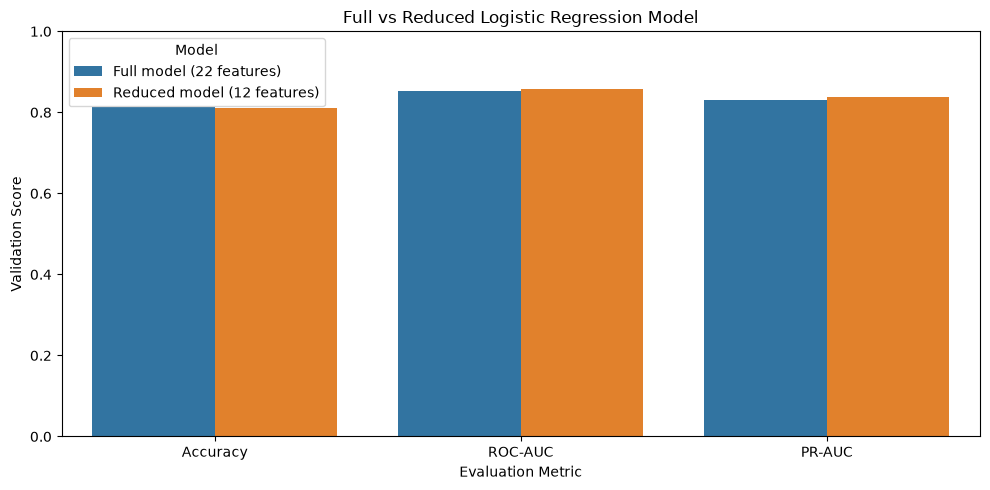

In [57]:

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    average_precision_score
)
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Candidate reduced feature set
selected_features = [
    "Tuition fees up to date",
    "Course",
    "Scholarship holder",
    "Application mode",
    "Age at enrollment",
    "Previous qualification (grade)",
    "Debtor",
    "Gender",
    "Admission grade",
    "Mother's occupation",
    "Father's occupation",
    "Unemployment rate"
]

# Identify feature types
selected_numerical = [
    col for col in selected_features
    if col in numerical_features
]

selected_categorical = [
    col for col in selected_features
    if col not in selected_numerical
]

# Build preprocessing for the reduced model
reduced_preprocessor = ColumnTransformer([
    ("num", StandardScaler(), selected_numerical),
    ("cat", OneHotEncoder(handle_unknown="ignore"),
     selected_categorical)
])

# Build reduced Logistic Regression pipeline
reduced_lr_pipeline = Pipeline([
    ("preprocessor", reduced_preprocessor),
    ("classifier", LogisticRegression(max_iter=2000))
])

# Train reduced model
reduced_lr_pipeline.fit(
    X_model_train[selected_features],
    y_model_train
)

# Predictions from full 22-feature model
full_prob = lr_pipeline.predict_proba(X_val)[:, 1]
full_pred = lr_pipeline.predict(X_val)

# Predictions from reduced 12-feature model
reduced_prob = reduced_lr_pipeline.predict_proba(
    X_val[selected_features]
)[:, 1]

reduced_pred = reduced_lr_pipeline.predict(
    X_val[selected_features]
)

# Compare results
comparison = pd.DataFrame([
    {
        "Model": "Full model (22 features)",
        "Accuracy": accuracy_score(y_val, full_pred),
        "ROC-AUC": roc_auc_score(y_val, full_prob),
        "PR-AUC": average_precision_score(y_val, full_prob)
    },
    {
        "Model": "Reduced model (12 features)",
        "Accuracy": accuracy_score(y_val, reduced_pred),
        "ROC-AUC": roc_auc_score(y_val, reduced_prob),
        "PR-AUC": average_precision_score(y_val, reduced_prob)
    }
])

display(comparison.round(4))

# Visualize model comparison
comparison_plot = comparison.melt(
    id_vars="Model",
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=comparison_plot,
    x="Metric",
    y="Score",
    hue="Model"
)

plt.ylim(0, 1)
plt.title("Full vs Reduced Logistic Regression Model")
plt.ylabel("Validation Score")
plt.xlabel("Evaluation Metric")
plt.tight_layout()
plt.show()


In [58]:
display(comparison.round(4))

,Model,Accuracy,ROC-AUC,PR-AUC
0,Full model (22 features),0.8141,0.8526,0.8315
1,Reduced model (12 features),0.8107,0.8587,0.8386


,Model,Dropout Precision,Dropout Recall,Dropout F1
0,Full (22 features),0.8251,0.6652,0.7366
1,Reduced (12 features),0.8305,0.6476,0.7277


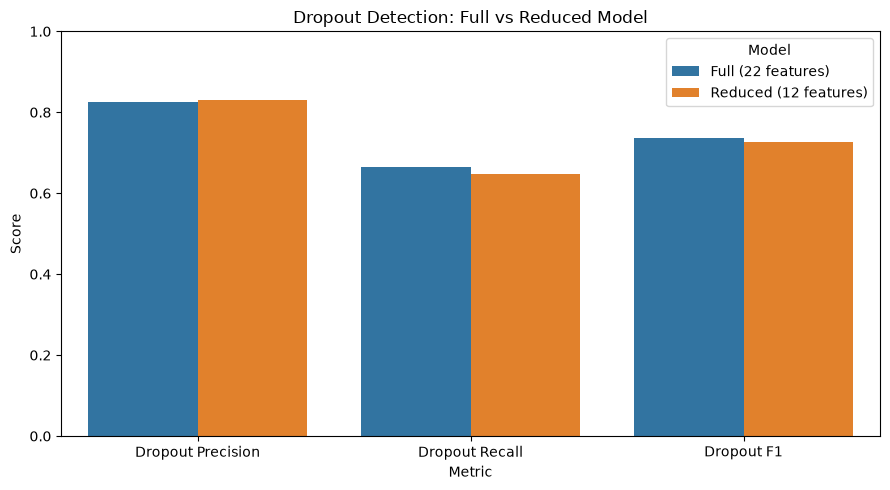

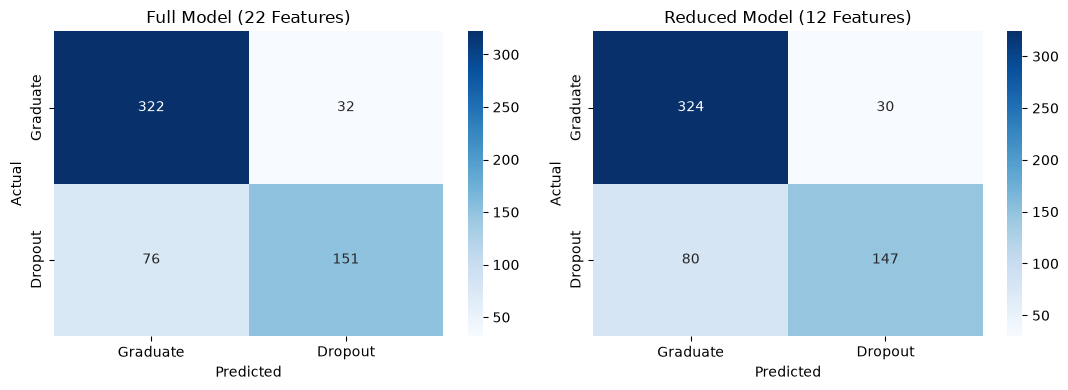

In [59]:

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    recall_score,
    f1_score,
    precision_score
)
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Compare dropout detection at the default 0.50 threshold
dropout_comparison = pd.DataFrame([
    {
        "Model": "Full (22 features)",
        "Dropout Precision": precision_score(y_val, full_pred),
        "Dropout Recall": recall_score(y_val, full_pred),
        "Dropout F1": f1_score(y_val, full_pred)
    },
    {
        "Model": "Reduced (12 features)",
        "Dropout Precision": precision_score(y_val, reduced_pred),
        "Dropout Recall": recall_score(y_val, reduced_pred),
        "Dropout F1": f1_score(y_val, reduced_pred)
    }
])

display(dropout_comparison.round(4))

# Visualize dropout detection metrics
plot_data = dropout_comparison.melt(
    id_vars="Model",
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=plot_data,
    x="Metric",
    y="Score",
    hue="Model"
)

plt.ylim(0, 1)
plt.title("Dropout Detection: Full vs Reduced Model")
plt.tight_layout()
plt.show()

# Confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for ax, predictions, title in [
    (axes[0], full_pred, "Full Model (22 Features)"),
    (axes[1], reduced_pred, "Reduced Model (12 Features)")
]:
    cm = confusion_matrix(y_val, predictions)

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Graduate", "Dropout"],
        yticklabels=["Graduate", "Dropout"],
        ax=ax
    )

    ax.set_title(title)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()


In [60]:
selected_features = [
    "Tuition fees up to date",
    "Course",
    "Scholarship holder",
    "Application mode",
    "Age at enrollment",
    "Previous qualification (grade)",
    "Debtor",
    "Gender",
    "Admission grade",
    "Mother's occupation",
    "Father's occupation",
    "Unemployment rate"
]

,Threshold,Accuracy,Dropout Precision,Dropout Recall,Dropout F1
0,0.20,0.6919,0.5682,0.8811,0.6908
1,0.25,0.7453,0.6312,0.8370,0.7197
2,0.30,0.7659,0.6643,0.8106,0.7302
3,0.35,0.7797,0.7004,0.7621,0.7300
4,0.40,0.7917,0.7387,0.7225,0.7305
5,0.45,0.8072,0.7833,0.7004,0.7395
6,0.50,0.8107,0.8305,0.6476,0.7277
7,0.55,0.8072,0.8662,0.5991,0.7083
8,0.60,0.8090,0.9028,0.5727,0.7008
9,0.65,0.7917,0.9077,0.5198,0.6611


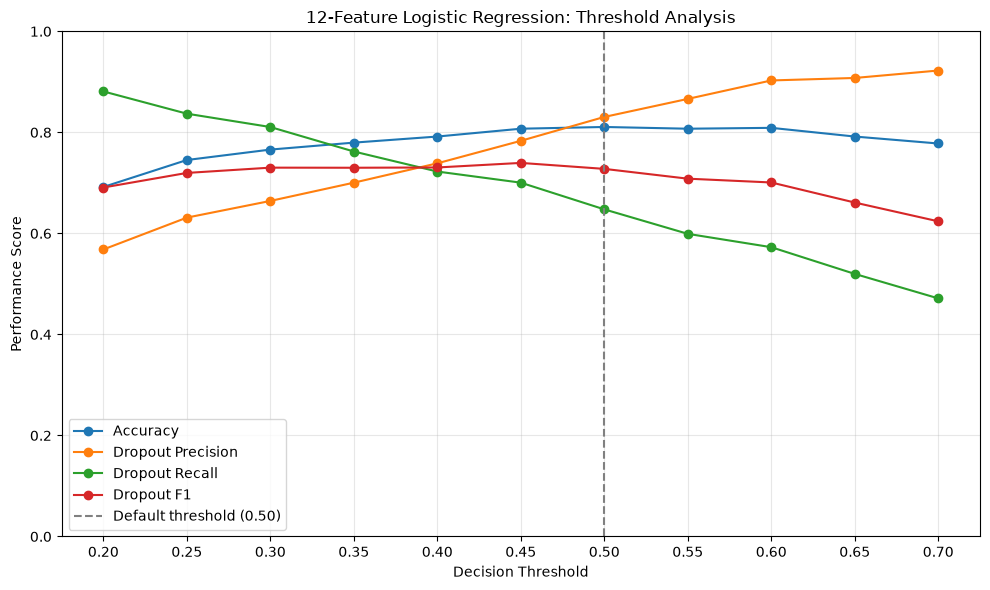

In [61]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Test different decision thresholds
thresholds = np.arange(0.20, 0.71, 0.05)

threshold_results = []

for threshold in thresholds:

    predictions = (reduced_prob >= threshold).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_val, predictions),
        "Dropout Precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "Dropout Recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "Dropout F1": f1_score(
            y_val, predictions, zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(4))


# Visualize threshold performance
plt.figure(figsize=(10, 6))

for metric in [
    "Accuracy",
    "Dropout Precision",
    "Dropout Recall",
    "Dropout F1"
]:
    plt.plot(
        threshold_df["Threshold"],
        threshold_df[metric],
        marker="o",
        label=metric
    )

plt.axvline(
    0.50,
    color="gray",
    linestyle="--",
    label="Default threshold (0.50)"
)

plt.title("12-Feature Logistic Regression: Threshold Analysis")
plt.xlabel("Decision Threshold")
plt.ylabel("Performance Score")
plt.xticks(thresholds.round(2))
plt.ylim(0, 1)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


In [62]:
FINAL_THRESHOLD = 0.40

print("Final model: Logistic Regression")
print("Number of features:", len(selected_features))
print("Decision threshold:", FINAL_THRESHOLD)
print("Positive class: Dropout")
print("\nSelected features:")

for feature in selected_features:
    print("-", feature)

Final model: Logistic Regression
Number of features: 12
Decision threshold: 0.4
Positive class: Dropout

Selected features:
- Tuition fees up to date
- Course
- Scholarship holder
- Application mode
- Age at enrollment
- Previous qualification (grade)
- Debtor
- Gender
- Admission grade
- Mother's occupation
- Father's occupation
- Unemployment rate


Final model trained successfully!
Training records: 2904
Selected features: 12
Decision threshold: 0.4

FINAL TEST RESULTS


,Accuracy,Dropout Precision,Dropout Recall,Dropout F1,ROC-AUC,PR-AUC
0,0.7658,0.6839,0.7465,0.7138,0.8539,0.8228



Classification Report:
              precision    recall  f1-score   support

    Graduate       0.83      0.78      0.80       442
     Dropout       0.68      0.75      0.71       284

    accuracy                           0.77       726
   macro avg       0.76      0.76      0.76       726
weighted avg       0.77      0.77      0.77       726



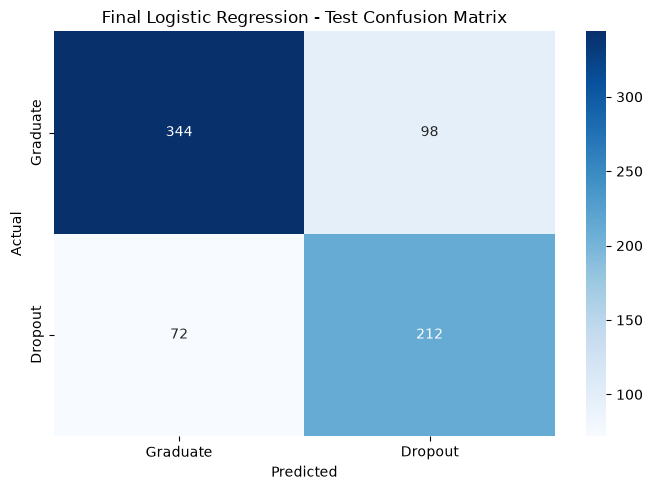

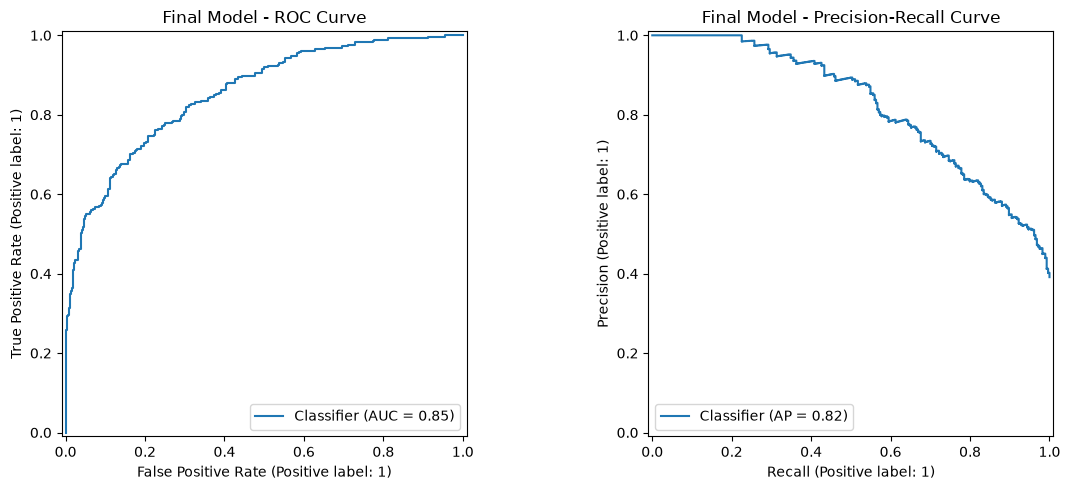

In [63]:

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    PrecisionRecallDisplay
)

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Final configuration
FINAL_THRESHOLD = 0.40

# 2. Identify feature types
selected_numerical = [
    col for col in selected_features
    if col in numerical_features
]

selected_categorical = [
    col for col in selected_features
    if col not in selected_numerical
]

# 3. Build final preprocessing pipeline
final_preprocessor = ColumnTransformer([
    ("num", StandardScaler(), selected_numerical),
    ("cat", OneHotEncoder(handle_unknown="ignore"),
     selected_categorical)
])

# 4. Build final Logistic Regression model
final_model = Pipeline([
    ("preprocessor", final_preprocessor),
    ("classifier", LogisticRegression(max_iter=2000))
])

# 5. Train using ALL training records
final_model.fit(
    X_train_fs[selected_features],
    y_train_fs
)

print("Final model trained successfully!")
print("Training records:", len(X_train_fs))
print("Selected features:", len(selected_features))
print("Decision threshold:", FINAL_THRESHOLD)

# 6. Predict probabilities on untouched test data
test_probabilities = final_model.predict_proba(
    X_test_fs[selected_features]
)[:, 1]

# Apply selected threshold
test_predictions = (
    test_probabilities >= FINAL_THRESHOLD
).astype(int)

# 7. Calculate final evaluation metrics
final_metrics = pd.DataFrame([{
    "Accuracy": accuracy_score(y_test_fs, test_predictions),
    "Dropout Precision": precision_score(
        y_test_fs, test_predictions
    ),
    "Dropout Recall": recall_score(
        y_test_fs, test_predictions
    ),
    "Dropout F1": f1_score(
        y_test_fs, test_predictions
    ),
    "ROC-AUC": roc_auc_score(
        y_test_fs, test_probabilities
    ),
    "PR-AUC": average_precision_score(
        y_test_fs, test_probabilities
    )
}])

print("\nFINAL TEST RESULTS")
display(final_metrics.round(4))

# 8. Detailed classification report
print("\nClassification Report:")
print(classification_report(
    y_test_fs,
    test_predictions,
    target_names=["Graduate", "Dropout"]
))

# 9. Confusion matrix
cm = confusion_matrix(
    y_test_fs,
    test_predictions,
    labels=[0, 1]
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Graduate", "Dropout"],
    yticklabels=["Graduate", "Dropout"]
)

plt.title("Final Logistic Regression - Test Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

# 10. ROC and Precision-Recall curves
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

RocCurveDisplay.from_predictions(
    y_test_fs,
    test_probabilities,
    ax=axes[0]
)
axes[0].set_title("Final Model - ROC Curve")

PrecisionRecallDisplay.from_predictions(
    y_test_fs,
    test_probabilities,
    ax=axes[1]
)
axes[1].set_title("Final Model - Precision-Recall Curve")

plt.tight_layout()
plt.show()


In [64]:

import joblib
import json
from pathlib import Path

# Locate project root
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

MODEL_DIR = PROJECT_ROOT / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Save the trained pipeline
model_path = MODEL_DIR / "student_dropout_model_12_features.joblib"

joblib.dump(final_model, model_path)

# Save model configuration
model_config = {
    "model_name": "Logistic Regression",
    "target": "Target",
    "positive_class": "Dropout",
    "positive_class_encoding": 1,
    "decision_threshold": FINAL_THRESHOLD,
    "selected_features": selected_features,
    "number_of_features": len(selected_features),
    "training_records": len(X_train_fs),
    "test_records": len(X_test_fs),
    "metrics": {
        "accuracy": 0.7658,
        "dropout_precision": 0.6839,
        "dropout_recall": 0.7465,
        "dropout_f1": 0.7138,
        "roc_auc": 0.8539,
        "pr_auc": 0.8228
    }
}

config_path = MODEL_DIR / "student_dropout_model_12_features_config.json"

with open(config_path, "w") as file:
    json.dump(model_config, file, indent=4)

print("Model saved:", model_path)
print("Configuration saved:", config_path)

print("\nModel files:")
for file in MODEL_DIR.glob("student_dropout_model_12_features*"):
    print(file.name, "-", round(file.stat().st_size / 1024, 2), "KB")


Model saved: /Users/mubhinbasnet/Desktop/student-dropout-prediction/models/student_dropout_model_12_features.joblib
Configuration saved: /Users/mubhinbasnet/Desktop/student-dropout-prediction/models/student_dropout_model_12_features_config.json

Model files:
student_dropout_model_12_features.joblib - 5.69 KB
student_dropout_model_12_features_config.json - 0.8 KB


In [65]:

import joblib
import numpy as np
import json

# Load saved model
loaded_model = joblib.load(
    MODEL_DIR / "student_dropout_model_12_features.joblib"
)

# Load configuration
with open(
    MODEL_DIR / "student_dropout_model_12_features_config.json"
) as file:
    loaded_config = json.load(file)

# Generate predictions using the loaded model
loaded_probabilities = loaded_model.predict_proba(
    X_test_fs[loaded_config["selected_features"]]
)[:, 1]

loaded_predictions = (
    loaded_probabilities >= loaded_config["decision_threshold"]
).astype(int)

# Compare against original model predictions
print("Model verification results")
print("--------------------------------")
print("Model loaded successfully:", loaded_model is not None)

print(
    "Probabilities identical:",
    np.allclose(test_probabilities, loaded_probabilities)
)

print(
    "Predictions identical:",
    np.array_equal(test_predictions, loaded_predictions)
)

print("Loaded features:", len(loaded_config["selected_features"]))
print("Loaded threshold:", loaded_config["decision_threshold"])

assert np.allclose(test_probabilities, loaded_probabilities)
assert np.array_equal(test_predictions, loaded_predictions)

print("\nSUCCESS: Saved model verified!")


Model verification results
--------------------------------
Model loaded successfully: True
Probabilities identical: True
Predictions identical: True
Loaded features: 12
Loaded threshold: 0.4

SUCCESS: Saved model verified!
